In [24]:
import os
import re
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from typing import Iterator, List, Dict

warnings.filterwarnings("ignore")

%config InlineBackend.figure_format = 'retina'
plt.rcParams['figure.figsize'] = 8, 5
plt.rcParams['font.size'] = 12
plt.rcParams['savefig.format'] = 'pdf'
sns.set_style('darkgrid')

PROJECT_PATH = Path('/home/frantsuaza/Documents/Science/SportLab/collusion_judges')

DATA_PATH = PROJECT_PATH / "data"
FIG_PATH = PROJECT_PATH / "reports" / "figures"
LIB_PATH = PROJECT_PATH / "collusion_judges"

CORR_PATH = FIG_PATH / "Corr_2"

In [ ]:
df_dict = {
    'corr': [],
    'rank': [], 
    'score': [], 
    'interval': [], 
    'name' : []
}
df = pd.DataFrame(df_dict)

corr_types = ('pearson', 'spearman', 'kendall')

axes, fig = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
fig.suptitle('Общий заголовок для всех графиков', fontsize=16)

for i, corr in enumerate(corr_types):
    data = df[df['corr']==corr]
    sns.lineplot(ax=axes[i], data=data, x='rank', y='score', ci='interval')
    axes[i].set_title(f'Топ аномальных судей для {corr}')
    axes[i].set_ylabel(f'Anomaly score по {corr}')
    axes[i].set_xlabel(f'Ранг аномальности по {corr}')

# Plot the anomalies

Example of how Isolation Forest partitions the feature space and constructs a tree. Anomalous judges tend to be isolated earlier (i.e., with fewer splits).

/tmp/ipykernel_78645/173857327.py:85: DeprecationWarning: Calling nonzero on 0d arrays is deprecated, as it behaves surprisingly. Use `atleast_1d(cond).nonzero()` if the old behavior was intended. If the context of this warning is of the form `arr[nonzero(cond)]`, just use `arr[cond]`.
  add_leaf_node(left_node, np.where(left_mask & ll_mask)[0], 2, "False", leaf_counter); leaf_counter += 1
/tmp/ipykernel_78645/173857327.py:86: DeprecationWarning: Calling nonzero on 0d arrays is deprecated, as it behaves surprisingly. Use `atleast_1d(cond).nonzero()` if the old behavior was intended. If the context of this warning is of the form `arr[nonzero(cond)]`, just use `arr[cond]`.
  add_leaf_node(left_node, np.where(left_mask & lr_mask)[0], 2, "True", leaf_counter); leaf_counter += 1
/tmp/ipykernel_78645/173857327.py:92: DeprecationWarning: Calling nonzero on 0d arrays is deprecated, as it behaves surprisingly. Use `atleast_1d(cond).nonzero()` if the old behavior was intended. If the context of 

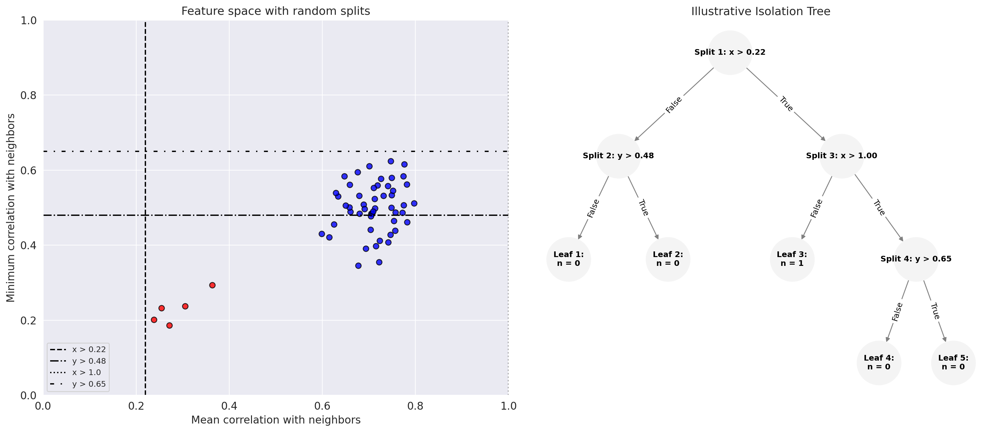

In [21]:
# Seed and data
np.random.seed(177)
n_normal = 50
n_anomalous = 5

x_normal = np.random.normal(loc=0.7, scale=0.05, size=n_normal)
y_normal = np.random.normal(loc=0.5, scale=0.07, size=n_normal)

x_anom = np.random.uniform(low=0.2, high=0.4, size=n_anomalous)
y_anom = np.random.uniform(low=0.1, high=0.3, size=n_anomalous)

x_all = np.concatenate([x_normal, x_anom])
y_all = np.concatenate([y_normal, y_anom])
labels = ["normal"] * n_normal + ["anomalous"] * n_anomalous

# Random split thresholds
x_1 = round(np.random.uniform(0.2, 0.6), 2)
x_2 = round(np.random.uniform(x_2, 1), 2)
y_1 = round(np.random.uniform(0.2, 0.5), 2)
y_2 = round(np.random.uniform(y_1, 0.8), 2)

# Split definitions with styles
split_lines = [
    {"label": f"x > {x_1}", "axis": "x", "value": x_1, "style": "--"},
    {"label": f"y > {y_1}", "axis": "y", "value": y_1, "style": "-."},
    {"label": f"x > {x_2}", "axis": "x", "value": x_2, "style": ":"},
    {"label": f"y > {y_2}", "axis": "y", "value": y_2, "style": (0, (3, 5, 1, 5))},
]

# Helper: get mask from condition
def apply_split(x, y, condition_str):
    return eval(condition_str)

# Tree traversal and label assignment
indices = np.arange(len(x_all))
splits = [
    ("x > {:.2f}".format(x_1), "Split 1"),
    ("y > {:.2f}".format(y_1), "Split 2"),
    ("x > {:.2f}".format(x_2), "Split 3"),
    ("y > {:.2f}".format(y_2), "Split 4"),
]

G = nx.DiGraph()
pos = {}
edge_labels = {}

# Start tree building
root_label = f"Split 1: x > {x_1}"
G.add_node(root_label)
pos[root_label] = (0.5, 1.0)

def add_split_node(parent, condition_str, name, level, branch):
    node_label = f"{name}: {condition_str.split('>')[0].strip()} > {condition_str.split('>')[1].strip()}"
    G.add_node(node_label)
    x_offset = -0.3 if branch == "False" else 0.3
    parent_x, parent_y = pos[parent]
    pos[node_label] = (parent_x + x_offset / (level + 1), parent_y - 0.2)
    G.add_edge(parent, node_label)
    edge_labels[(parent, node_label)] = branch
    return node_label

def add_leaf_node(parent, indices, level, branch, leaf_num):
    node_label = f"Leaf {leaf_num}:\nn = {len(indices)}"
    G.add_node(node_label)
    x_offset = -0.2 if branch == "False" else 0.2
    parent_x, parent_y = pos[parent]
    pos[node_label] = (parent_x + x_offset / (level + 1), parent_y - 0.2)
    G.add_edge(parent, node_label)
    edge_labels[(parent, node_label)] = branch

# Traverse tree and assign points to leaves
leaf_counter = 1
root_mask = eval(splits[0][0])
left_mask = ~root_mask
right_mask = root_mask

# Left side
left_node = add_split_node(root_label, splits[1][0], "Split 2", 1, "False")
ll_mask = ~eval(splits[1][0])
lr_mask = eval(splits[1][0])
add_leaf_node(left_node, np.where(left_mask & ll_mask)[0], 2, "False", leaf_counter); leaf_counter += 1
add_leaf_node(left_node, np.where(left_mask & lr_mask)[0], 2, "True", leaf_counter); leaf_counter += 1

# Right side
right_node = add_split_node(root_label, splits[2][0], "Split 3", 1, "True")
rl_mask = ~eval(splits[2][0])
rr_mask = eval(splits[2][0])
add_leaf_node(right_node, np.where(right_mask & rl_mask)[0], 2, "False", leaf_counter); leaf_counter += 1

# Final split for right-right branch
sub_node = add_split_node(right_node, splits[3][0], "Split 4", 2, "True")
subl_mask = ~eval(splits[3][0])
subr_mask = eval(splits[3][0])
add_leaf_node(sub_node, np.where(right_mask & rr_mask & subl_mask)[0], 3, "False", leaf_counter); leaf_counter += 1
add_leaf_node(sub_node, np.where(right_mask & rr_mask & subr_mask)[0], 3, "True", leaf_counter); leaf_counter += 1

# Plotting
fig, axs = plt.subplots(1, 2, figsize=(16, 7))

# Left: feature space
for x, y, label in zip(x_all, y_all, labels):
    axs[0].scatter(x, y, c='red' if label == 'anomalous' else 'blue', s=40, alpha=0.8, edgecolor='black')

for split in split_lines:
    if split["axis"] == "x":
        axs[0].axvline(split["value"], color="black", linestyle=split["style"], label=split["label"])
    else:
        axs[0].axhline(split["value"], color="black", linestyle=split["style"], label=split["label"])

axs[0].set_xlim(0, 1)
axs[0].set_ylim(0, 1)
axs[0].set_title("Feature space with random splits", fontsize=13)
axs[0].set_xlabel("Mean correlation with neighbors")
axs[0].set_ylabel("Minimum correlation with neighbors")
axs[0].legend(loc="lower left", fontsize=9)

# Right: Tree
nx.draw(G, pos=pos, ax=axs[1], with_labels=True, node_size=2500, node_color="#F4F4F4",
        font_size=9, font_weight='bold', edge_color="gray", arrows=True)
nx.draw_networkx_edge_labels(G, pos=pos, edge_labels=edge_labels, font_size=9)

axs[1].set_title("Illustrative Isolation Tree", fontsize=13)
axs[1].axis('off')

plt.tight_layout()
plt.show()


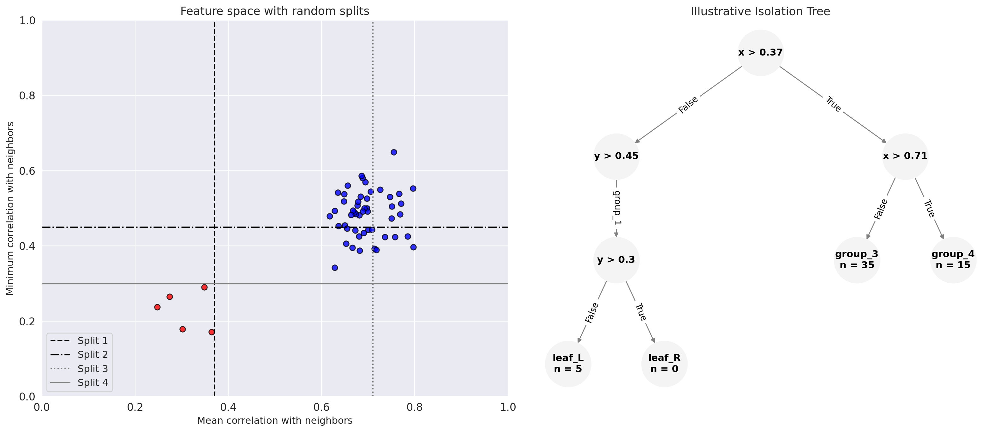

In [32]:
n_normal, n_anomalous = 50, 5
x_normal = np.random.normal(loc=0.7, scale=0.05, size=n_normal)
y_normal = np.random.normal(loc=0.5, scale=0.07, size=n_normal)
x_anom = np.random.uniform(low=0.2, high=0.4, size=n_anomalous)
y_anom = np.random.uniform(low=0.1, high=0.3, size=n_anomalous)

x_all = np.concatenate([x_normal, x_anom])
y_all = np.concatenate([y_normal, y_anom])
labels = ["normal"] * n_normal + ["anomalous"] * n_anomalous

# Choose valid split thresholds
x_1 = round(np.random.uniform(0.3, 0.6), 2)
x_2 = round(np.random.uniform(0.7, 0.9), 2)
y_1 = round(np.random.uniform(0.3, 0.5), 2)

# Decide which group to split with y_2 (group 1 or 2 or goup 3 or group 4)
group1 = (x_all < x_1) & (y_all < y_1)
group2 = (x_all < x_1) & (y_all > y_1)

if group1.sum() > group2.sum():
    group_to_split = group1
    y_2 = round(np.random.uniform(0.1, y_1), 2)
    attach_to = "group_1"
else:
    group_to_split = group2
    y_2 = round(np.random.uniform(y_1 , 0.8), 2)
    attach_to = "group_2"

# Count leaf sizes
group_1 = (x_all < x_1) & (y_all < y_1)
group_2 = (x_all < x_1) & (y_all > y_1)
group_3 = (x_all > x_1) & (x_all < x_2)
group_4 = (x_all > x_1) & (x_all > x_2)

if attach_to == "group_1":
    leaf_left = (x_all < x_1) & (y_all < y_1) & (y_all < y_2)
    leaf_right = (x_all < x_1) & (y_all < y_1) & (y_all > y_2)
else:
    leaf_left = (x_all < x_1) & (y_all > y_1) & (y_all < y_2)
    leaf_right = (x_all < x_1) & (y_all > y_1) & (y_all > y_2)

# Prepare graph
G = nx.DiGraph()
root = f"x > {x_1}"
G.add_node(root)
left_node = f"y > {y_1}"
right_node = f"x > {x_2}"
G.add_node(left_node)
G.add_node(right_node)
G.add_edge(root, left_node, label="False")
G.add_edge(root, right_node, label="True")

# Leaf nodes
G.add_node("group_3\nn = {}".format(group_3.sum()))
G.add_edge(right_node, "group_3\nn = {}".format(group_3.sum()), label="False")
G.add_node("group_4\nn = {}".format(group_4.sum()))
G.add_edge(right_node, "group_4\nn = {}".format(group_4.sum()), label="True")

# Attach y_2 split
split_y2 = f"y > {y_2}"
G.add_node(split_y2)
G.add_edge(left_node, split_y2, label="{}".format(attach_to))

# Leaves for split_y2
G.add_node("leaf_L\nn = {}".format(leaf_left.sum()))
G.add_edge(split_y2, "leaf_L\nn = {}".format(leaf_left.sum()), label="False")
G.add_node("leaf_R\nn = {}".format(leaf_right.sum()))
G.add_edge(split_y2, "leaf_R\nn = {}".format(leaf_right.sum()), label="True")

# Layout
pos = {
    root: (0.5, 1.0),
    left_node: (0.2, 0.75),
    right_node: (0.8, 0.75),
    split_y2: (0.2, 0.5),
    "leaf_L\nn = {}".format(leaf_left.sum()): (0.1, 0.25),
    "leaf_R\nn = {}".format(leaf_right.sum()): (0.3, 0.25),
    "group_3\nn = {}".format(group_3.sum()): (0.7, 0.5),
    "group_4\nn = {}".format(group_4.sum()): (0.9, 0.5)
}

# Plot
fig, axs = plt.subplots(1, 2, figsize=(16, 7))

# Left plot
for x, y, label in zip(x_all, y_all, labels):
    axs[0].scatter(x, y, c='red' if label == 'anomalous' else 'blue', s=40, edgecolor='black', alpha=0.8)

axs[0].axvline(x_1, color='black', linestyle='--', label='Split 1')
axs[0].axhline(y_1, color='black', linestyle='-.', label='Split 2')
axs[0].axvline(x_2, color='gray', linestyle=':', label='Split 3')
axs[0].axhline(y_2, color='gray', linestyle='-', label='Split 4')
axs[0].set_xlim(0, 1)
axs[0].set_ylim(0, 1)
axs[0].legend(loc="lower left", fontsize=11)
axs[0].set_title("Feature space with random splits", fontsize=13)
axs[0].set_xlabel("Mean correlation with neighbors", fontsize=11)
axs[0].set_ylabel("Minimum correlation with neighbors", fontsize=11)

# Right plot
nx.draw(G, pos=pos, ax=axs[1], with_labels=True, node_size=2700, node_color="#F4F4F4",
        font_size=11, font_weight='bold', edge_color="gray", arrows=True)
edge_labels = nx.get_edge_attributes(G, 'label')
nx.draw_networkx_edge_labels(G, pos=pos, edge_labels=edge_labels, font_size=10)
axs[1].set_title("Illustrative Isolation Tree", fontsize=13)
axs[1].axis('off')

plt.tight_layout()
plt.savefig("figures/isolation_tree_diagram.png", dpi=300, bbox_inches='tight')
plt.show()


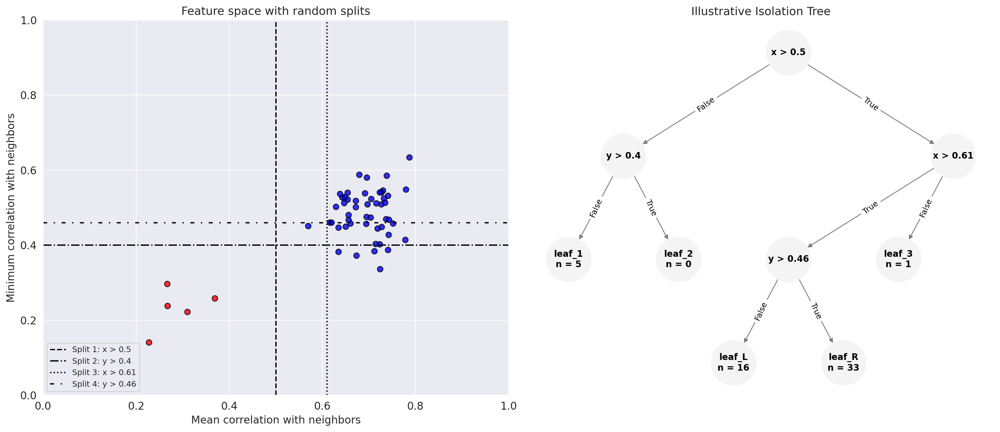

In [39]:
# Re-execute entire process to ensure output is generated and saved

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import os

# Seed and data

n_normal = 50
n_anomalous = 5

x_normal = np.random.normal(loc=0.7, scale=0.05, size=n_normal)
y_normal = np.random.normal(loc=0.5, scale=0.07, size=n_normal)
x_anom = np.random.uniform(low=0.2, high=0.4, size=n_anomalous)
y_anom = np.random.uniform(low=0.1, high=0.3, size=n_anomalous)

x_all = np.concatenate([x_normal, x_anom])
y_all = np.concatenate([y_normal, y_anom])
labels = ["normal"] * n_normal + ["anomalous"] * n_anomalous

# Generate random thresholds with correct ordering
x_1 = round(np.random.uniform(0.25, 0.6), 2)
x_2 = round(np.random.uniform(x_1 , 0.8), 2)
y_1 = round(np.random.uniform(0.3, 0.6), 2)

group_1 = (x_all < x_1) & (y_all < y_1)
group_2 = (x_all < x_1) & (y_all > y_1)
group_3 = (x_all > x_1) & (x_all < x_2)
group_4 = (x_all > x_1) & (x_all > x_2)

groups = [group_1, group_2, group_3, group_4]
group_sizes = [g.sum() for g in groups]
max_index = int(np.argmax(group_sizes))
group_to_split = groups[max_index]

if max_index in [0, 2]:
    y_2 = round(np.random.uniform(0.1, y_1), 2)
    y2_dir = "y < {:.2f}".format(y_2)
else:
    y_2 = round(np.random.uniform(y_1 + 0.01, 0.7), 2)
    y2_dir = "y > {:.2f}".format(y_2)

if ">" in y2_dir:
    leaf_left = group_to_split & (y_all <= y_2)
    leaf_right = group_to_split & (y_all > y_2)
else:
    leaf_left = group_to_split & (y_all < y_2)
    leaf_right = group_to_split & (y_all >= y_2)

root = f"x > {x_1}"
left_node = f"y > {y_1}"
right_node = f"x > {x_2}"
split_y2 = y2_dir

G = nx.DiGraph()
G.add_node(root)
G.add_node(left_node)
G.add_node(right_node)
G.add_edge(root, left_node, label="False")
G.add_edge(root, right_node, label="True")

leaf_nodes = {}
leaf_labels = ["leaf_1", "leaf_2", "leaf_3", "leaf_4"]
leaf_groups = [group_1, group_2, group_3, group_4]

for i, (grp, label) in enumerate(zip(leaf_groups, leaf_labels)):
    if i == max_index:
        continue
    leaf_name = f"{label}\nn = {grp.sum()}"
    G.add_node(leaf_name)
    if i == 0:
        G.add_edge(left_node, leaf_name, label="False")
    elif i == 1:
        G.add_edge(left_node, leaf_name, label="True")
    elif i == 2:
        G.add_edge(right_node, leaf_name, label="False")
    elif i == 3:
        G.add_edge(right_node, leaf_name, label="True")

G.add_node(split_y2)
if max_index == 0:
    G.add_edge(left_node, split_y2, label="False")
elif max_index == 1:
    G.add_edge(left_node, split_y2, label="True")
elif max_index == 2:
    G.add_edge(right_node, split_y2, label="False")
elif max_index == 3:
    G.add_edge(right_node, split_y2, label="True")

left_leaf_label = f"leaf_L\nn = {leaf_left.sum()}"
right_leaf_label = f"leaf_R\nn = {leaf_right.sum()}"
G.add_node(left_leaf_label)
G.add_node(right_leaf_label)
G.add_edge(split_y2, left_leaf_label, label="False")
G.add_edge(split_y2, right_leaf_label, label="True")

pos = {
    root: (0.5, 1.0),
    left_node: (0.2, 0.75),
    right_node: (0.8, 0.75),
    split_y2: (0.5, 0.5),
    left_leaf_label: (0.4, 0.25),
    right_leaf_label: (0.6, 0.25),
}

leaf_pos_map = [("leaf_1", 0.1), ("leaf_2", 0.3), ("leaf_3", 0.7), ("leaf_4", 0.9)]
for i, (label, x) in enumerate(leaf_pos_map):
    if i == max_index:
        continue
    name = f"{label}\nn = {leaf_groups[i].sum()}"
    pos[name] = (x, 0.5)

fig, axs = plt.subplots(1, 2, figsize=(16, 7))

for x, y, label in zip(x_all, y_all, labels):
    axs[0].scatter(x, y, c='red' if label == 'anomalous' else 'blue', s=40, alpha=0.8, edgecolor='black')

axs[0].axvline(x_1, linestyle="--", color="black", label=f"Split 1: x > {x_1}")
axs[0].axhline(y_1, linestyle="-.", color="black", label=f"Split 2: y > {y_1}")
axs[0].axvline(x_2, linestyle=":", color="black", label=f"Split 3: x > {x_2}")
axs[0].axhline(y_2, linestyle=(0, (3, 5, 1, 5)), color="black", label=f"Split 4: {y2_dir}")
axs[0].set_xlim(0, 1)
axs[0].set_ylim(0, 1)
axs[0].set_title("Feature space with random splits", fontsize=13)
axs[0].set_xlabel("Mean correlation with neighbors")
axs[0].set_ylabel("Minimum correlation with neighbors")
axs[0].legend(loc="lower left", fontsize=9)

nx.draw(G, pos=pos, ax=axs[1], with_labels=True, node_size=2600, node_color="#F4F4F4",
        font_size=10, font_weight='bold', edge_color="gray", arrows=True)
nx.draw_networkx_edge_labels(G, pos=pos,
                             edge_labels={(u, v): d["label"] for u, v, d in G.edges(data=True)},
                             font_size=9)
axs[1].set_title("Illustrative Isolation Tree", fontsize=13)
axs[1].axis('off')

plt.tight_layout()
plt.savefig("figures/isolation_tree_diagram.png", dpi=300, bbox_inches='tight')
plt.show()


# Graph description

In [94]:
node_df = pd.read_excel('nodes_dataframe_new.xlsx')


In [96]:
node_df.columns

Index(['name', 'degree', 'n_events', 'country', 'pearson_mean',
       'pearson_median', 'pearson_min', 'pearson_max', 'pearson_std',
       'pearson_fisher_mean', 'spearman_mean', 'spearman_median',
       'spearman_min', 'spearman_max', 'spearman_std', 'kendall_mean',
       'kendall_median', 'kendall_min', 'kendall_max', 'kendall_std',
       'pearson_mean_betweenness', 'pearson_mean_closeness',
       'pearson_mean_eigenvector', 'pearson_mean_clustering',
       'pearson_median_betweenness', 'pearson_median_closeness',
       'pearson_median_eigenvector', 'pearson_median_clustering',
       'spearman_mean_betweenness', 'spearman_mean_closeness',
       'spearman_mean_eigenvector', 'spearman_mean_clustering',
       'spearman_median_betweenness', 'spearman_median_closeness',
       'spearman_median_eigenvector', 'spearman_median_clustering',
       'kendall_mean_betweenness', 'kendall_mean_closeness',
       'kendall_mean_eigenvector', 'kendall_mean_clustering',
       'kendall_medi

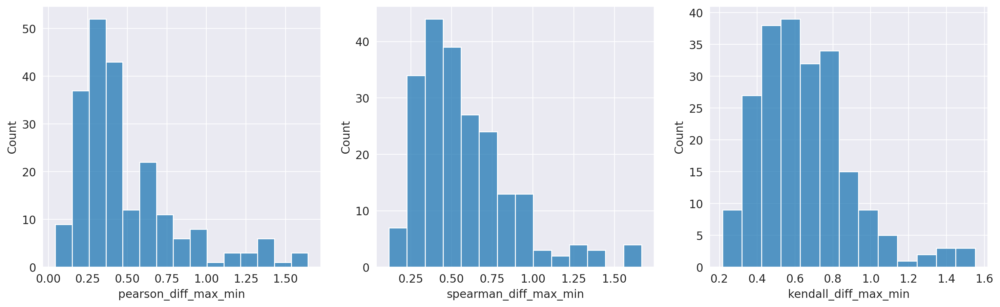

In [98]:
corr_types = ('pearson', 'spearman', 'kendall')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, corr in enumerate(corr_types):
    node_df[f'{corr}_diff_max_min'] = node_df[f'{corr}_max'] - node_df[f'{corr}_min'] 
    sns.histplot(ax = axes[i] , data = node_df, x = f'{corr}_diff_max_min')

In [99]:
def plot_box_and_hist(
    df: pd.DataFrame,
    col: str,
    title: str,
    bins: int = 30,
    figsize=(12, 4)
):
    fig, axes = plt.subplots(1, 2, figsize=figsize)

    # Boxplot
    sns.boxplot(
        y=df[col],
        ax=axes[0],
        color="#4C72B0"
    )
    axes[0].set_title(f"{title} (boxplot)")
    axes[0].set_ylabel("")

    # Histogram
    sns.histplot(
        df[col],
        bins=bins,
        kde=True,
        ax=axes[1],
        color="#55A868"
    )
    axes[1].set_title(f"{title} (histogram)")
    axes[1].set_xlabel("")

    plt.tight_layout()
    plt.show()


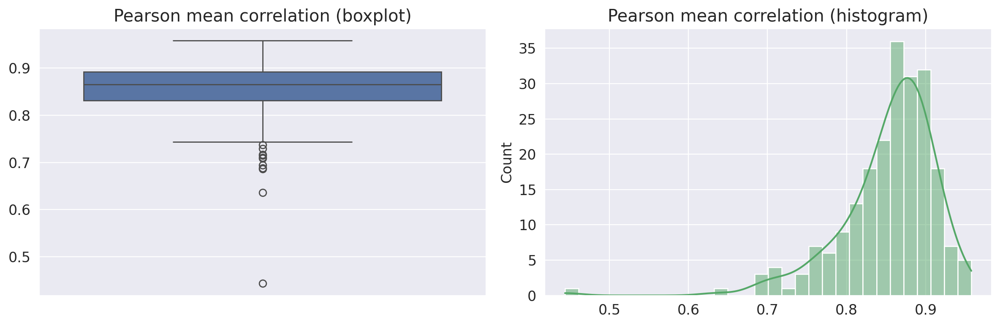

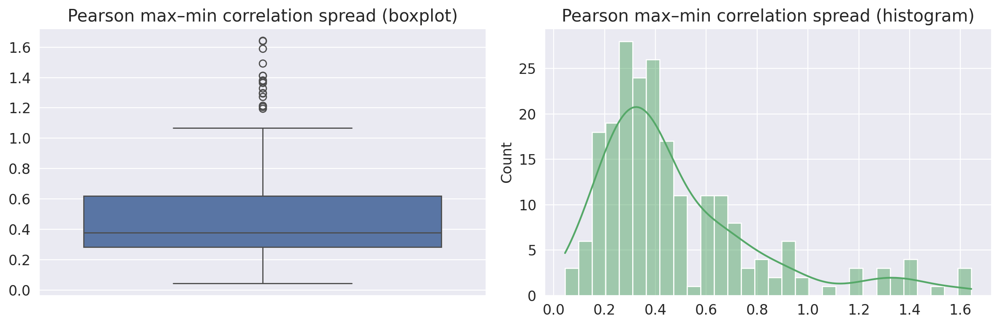

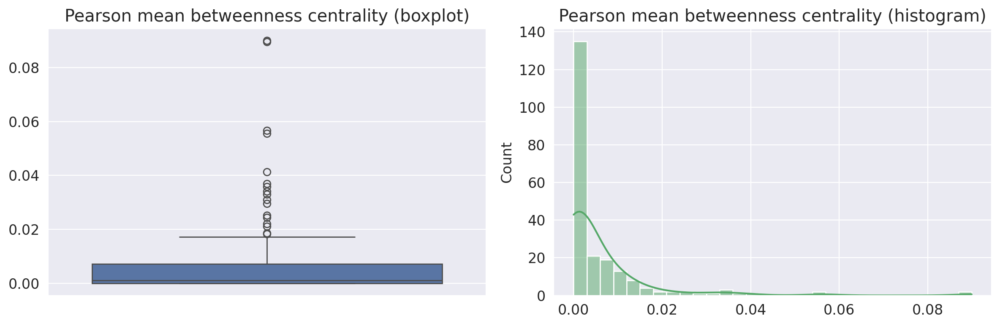

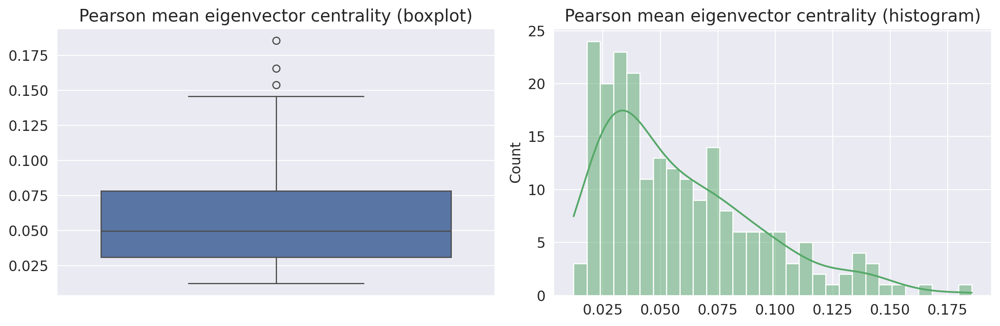

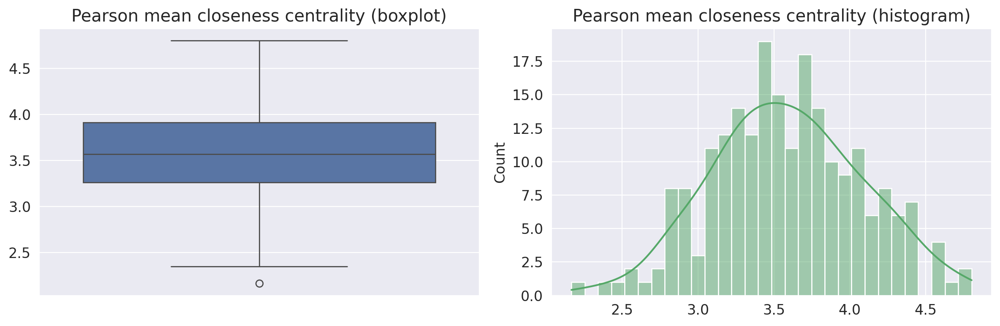

...

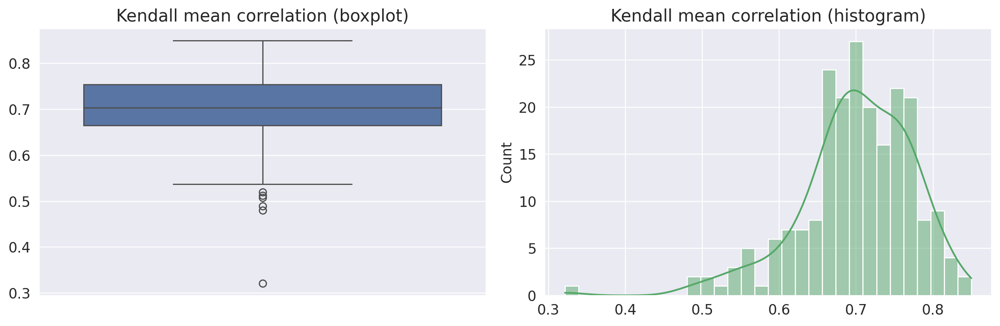

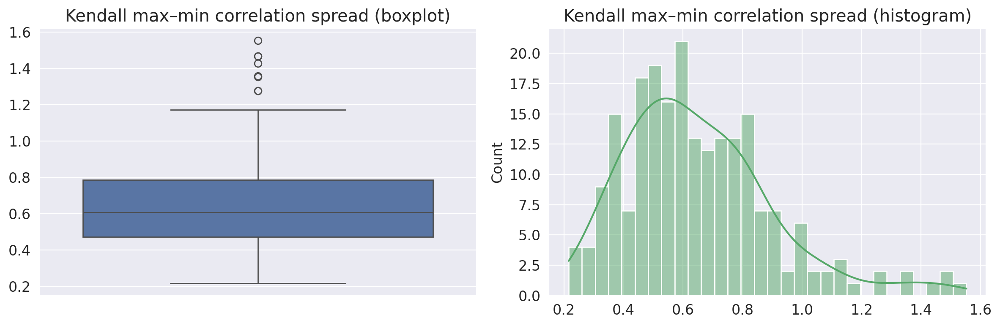

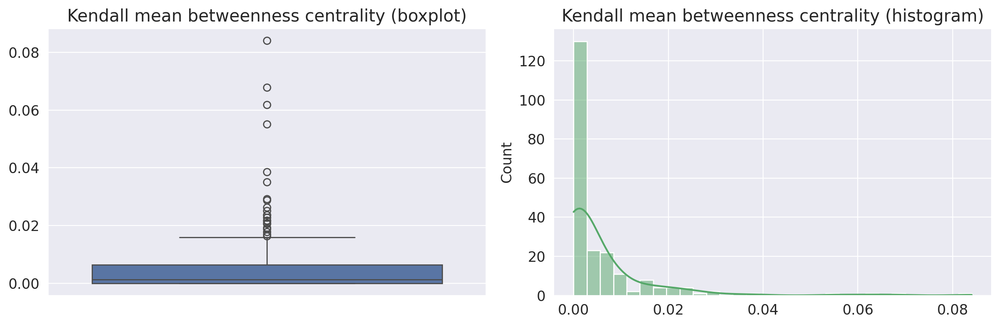

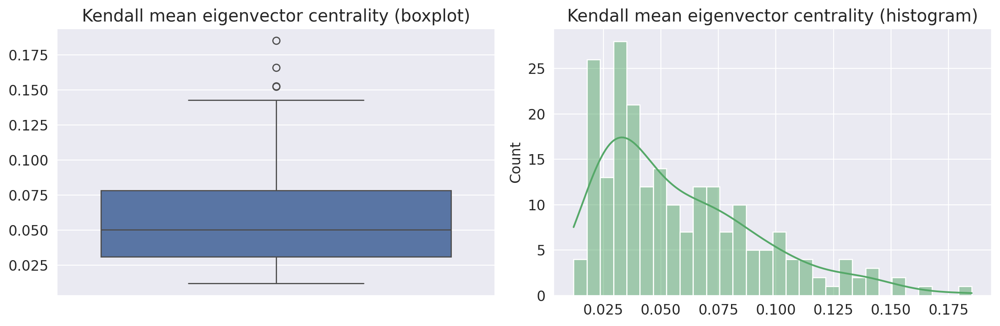

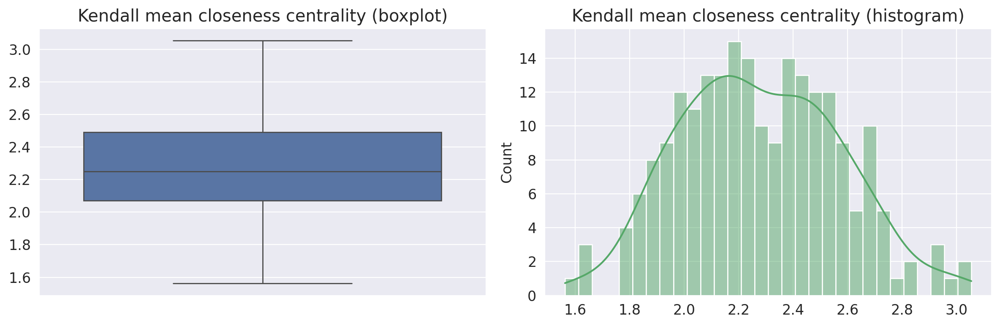

In [101]:
for corr in ["pearson", "spearman", "kendall"]:
    plot_box_and_hist(
        node_df,
        f"{corr}_mean",
        title=f"{corr.capitalize()} mean correlation"
    )

    plot_box_and_hist(
        node_df,
        f"{corr}_diff_max_min",
        title=f"{corr.capitalize()} max–min correlation spread"
    )

    plot_box_and_hist(
        node_df,
        f"{corr}_mean_betweenness",
        title=f"{corr.capitalize()} mean betweenness centrality"
    )

    plot_box_and_hist(
        node_df,
        f"{corr}_mean_eigenvector",
        title=f"{corr.capitalize()} mean eigenvector centrality"
    )

    plot_box_and_hist(
        node_df,
        f"{corr}_mean_closeness",
        title=f"{corr.capitalize()} mean closeness centrality"
    )


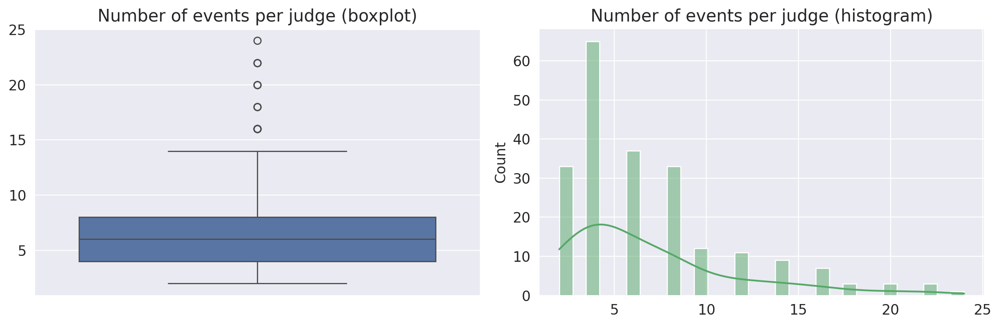

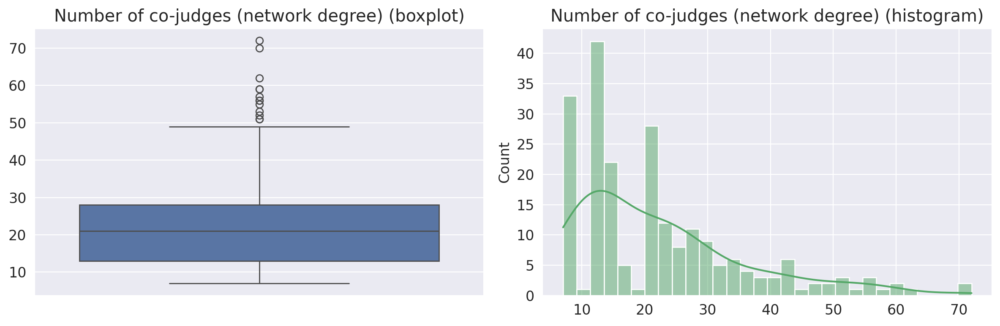

In [102]:
plot_box_and_hist(
    node_df,
    "n_events",
    title="Number of events per judge"
)

plot_box_and_hist(
    node_df,
    "degree",
    title="Number of co-judges (network degree)"
)


In [112]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_box_and_hist(
    df: pd.DataFrame,
    col: str,
    title: str = "",
    xlabel: str = "",
    ylabel: str = "",
    bins: int = 30,
    kde: bool = True,
    figsize: tuple = (12, 4),
    fig_name: str = "",          # e.g. "figures/n_events_box_hist.png"
    dpi: int = 300
):
    """
    Draws a boxplot (left) and histogram (right) for a numeric column.
    Optionally saves the figure if fig_name is provided (non-empty).

    Returns
    -------
    fig, axes
    """
    x = df[col].dropna()

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    # --- Boxplot
    sns.boxplot(y=x, ax=axes[0])
    axes[0].set_title("Boxplot" if not title else f"{title}")
    axes[0].set_xlabel("")
    axes[0].set_ylabel(ylabel)

    # --- Histogram
    sns.histplot(x, bins=bins, kde=kde, ax=axes[1])
    axes[1].set_title("Histogram" if not title else f"{title}")
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel("Count")

    plt.tight_layout()

    # --- Save if requested
    if fig_name:
        os.makedirs(os.path.dirname(fig_name), exist_ok=True)
        fig.savefig(fig_name, dpi=dpi, bbox_inches="tight")
        print(f"[SAVED] {fig_name}")

    plt.show()
    plt.close(fig)

    return fig, axes


[SAVED] figures/n_events_box_hist.png


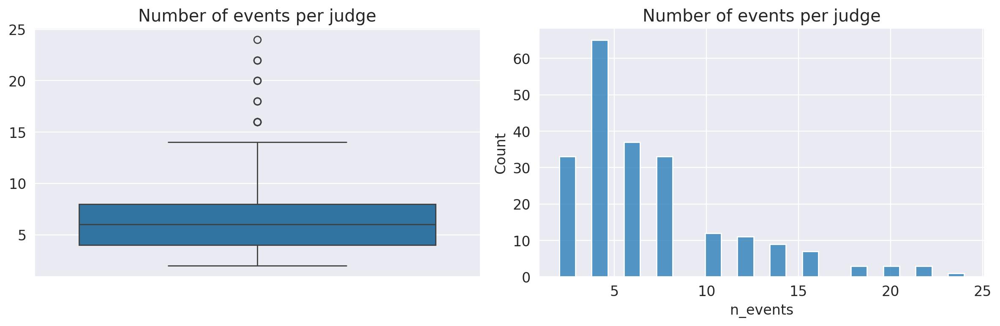

(<Figure size 1200x400 with 2 Axes>,
 array([<Axes: title={'center': 'Number of events per judge'}>,
        <Axes: title={'center': 'Number of events per judge'}, xlabel='n_events', ylabel='Count'>],
       dtype=object))

In [106]:
plot_box_and_hist(
    node_df,
    col="n_events",
    title="Number of events per judge",
    xlabel="n_events",
    ylabel="",
    bins=25,
    kde=False,  # <- removes the smooth curve
    fig_name="figures/n_events_box_hist.png"
)


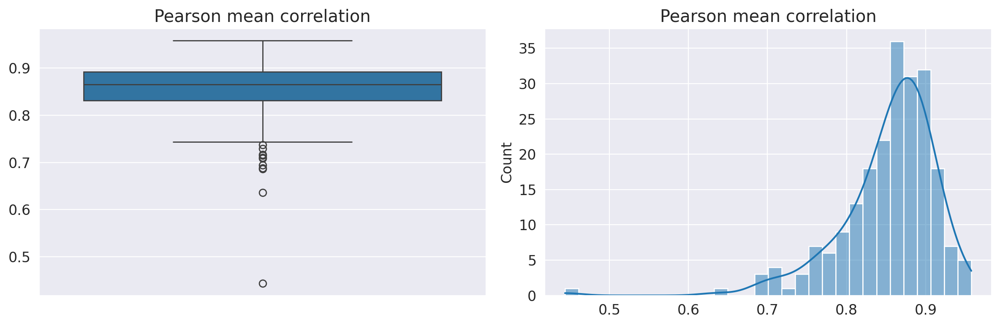

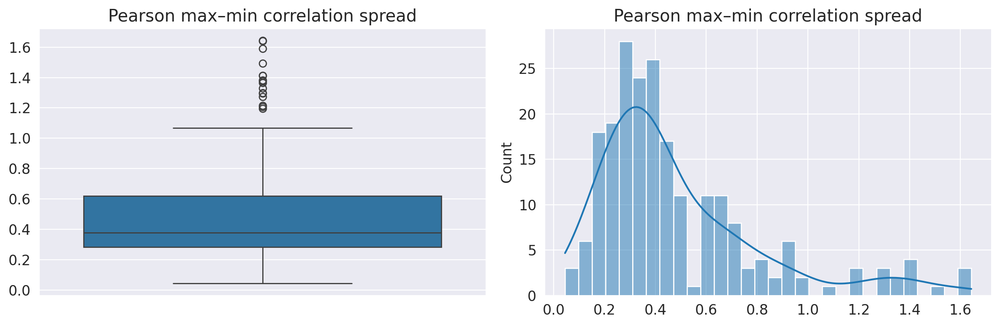

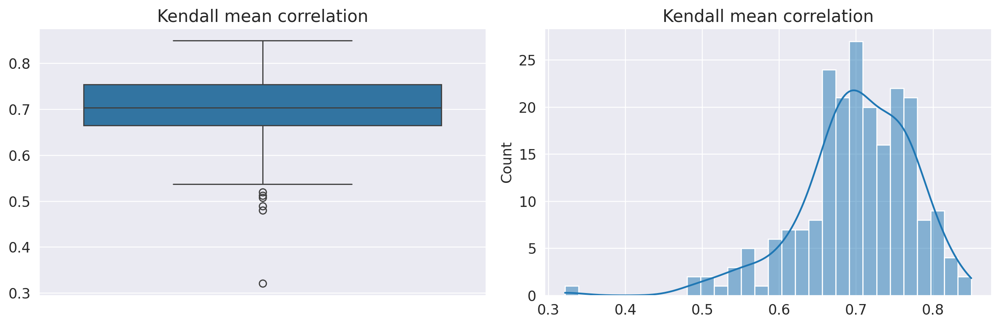

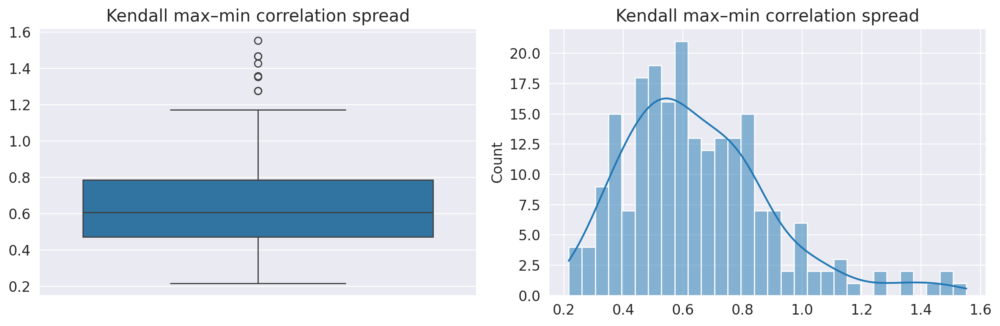

In [113]:
for corr in ["pearson", "kendall"]:
    plot_box_and_hist(
        node_df,
        f"{corr}_mean",
        title=f"{corr.capitalize()} mean correlation",
        kde=True
    )

    plot_box_and_hist(
        node_df,
        f"{corr}_diff_max_min",
        title=f"{corr.capitalize()} max–min correlation spread",
        kde=True
    )

In [114]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_two_histplots(
    df: pd.DataFrame,
    col_left: str,
    col_right: str,
    title: str = "",
    bins: int = 30,
    kde: bool = True,
    figsize=(12, 4),
    xlim=None,              # tuple (xmin, xmax) applied to both if xlim_left/right are None
    ylim=None,              # tuple (ymin, ymax) applied to both if ylim_left/right are None
    xlim_left=None,         # optional tuple (xmin, xmax) for left
    xlim_right=None,        # optional tuple (xmin, xmax) for right
    ylim_left=None,         # optional tuple (ymin, ymax) for left
    ylim_right=None,        # optional tuple (ymin, ymax) for right
    xlabel_left="",
    xlabel_right="",
    ylabel="Count",
    fig_name: str = "",
    dpi: int = 300
):
    """
    One figure with two histplots (left + right). Optionally save.

    Parameters
    ----------
    xlim/ylim: global axis limits applied to both subplots unless
               xlim_left/right or ylim_left/right are provided.
    """

    x1 = df[col_left].dropna()
    x2 = df[col_right].dropna()

    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=False)

    # --- Left histogram
    sns.histplot(x1, bins=bins, kde=kde, ax=axes[0])
    axes[0].set_title(col_left.replace("_", " "))
    axes[0].set_xlabel(xlabel_left if xlabel_left else col_left)
    axes[0].set_ylabel(ylabel)

    # --- Right histogram
    sns.histplot(x2, bins=bins, kde=kde, ax=axes[1])
    axes[1].set_title(col_right.replace("_", " "))
    axes[1].set_xlabel(xlabel_right if xlabel_right else col_right)
    axes[1].set_ylabel(ylabel)

    # --- Apply axis limits (global fallback + per-axis overrides)
    if xlim is not None:
        axes[0].set_xlim(*xlim)
        axes[1].set_xlim(*xlim)
    if ylim is not None:
        axes[0].set_ylim(*ylim)
        axes[1].set_ylim(*ylim)

    if xlim_left is not None:
        axes[0].set_xlim(*xlim_left)
    if xlim_right is not None:
        axes[1].set_xlim(*xlim_right)

    if ylim_left is not None:
        axes[0].set_ylim(*ylim_left)
    if ylim_right is not None:
        axes[1].set_ylim(*ylim_right)

    # --- Title
    if title:
        fig.suptitle(title, y=1.03)

    plt.tight_layout()

    # --- Save
    if fig_name:
        os.makedirs(os.path.dirname(fig_name), exist_ok=True)
        fig.savefig(fig_name, dpi=dpi, bbox_inches="tight")
        print(f"[SAVED] {fig_name}")

    plt.show()
    plt.close(fig)

    return fig, axes


[SAVED] figures/comparison_pearson_kendall_mean.png


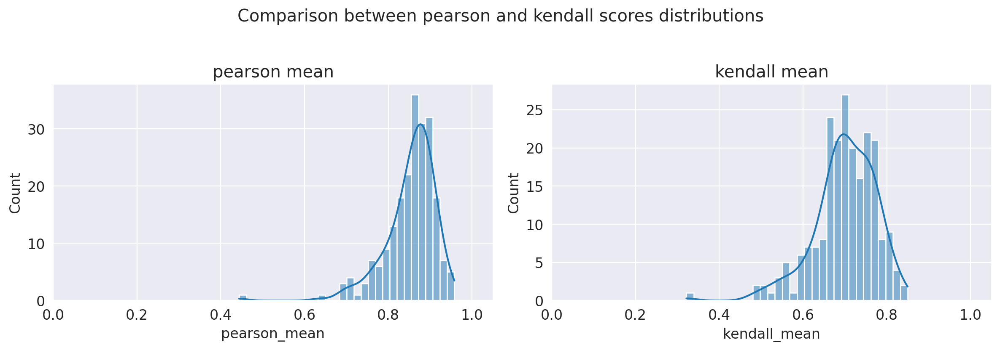

[SAVED] figures/comparison_pearson_kendall_maxmin.png


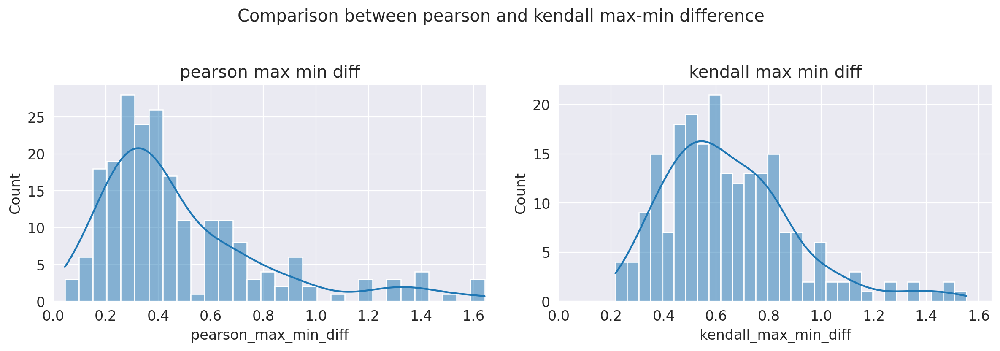

(<Figure size 1200x400 with 2 Axes>,
 array([<Axes: title={'center': 'pearson max min diff'}, xlabel='pearson_max_min_diff', ylabel='Count'>,
        <Axes: title={'center': 'kendall max min diff'}, xlabel='kendall_max_min_diff', ylabel='Count'>],
       dtype=object))

In [117]:
node_df["pearson_max_min_diff"] = node_df["pearson_max"] - node_df["pearson_min"]
node_df["kendall_max_min_diff"] = node_df["kendall_max"] - node_df["kendall_min"]


plot_two_histplots(
    node_df,
    col_left="pearson_mean",
    col_right="kendall_mean",
    title="Comparison between pearson and kendall scores distributions",
    bins=30,
    kde=True,
    xlim_left=(0, 1.05),
    xlim_right=(0.0, 1.05),
    fig_name="figures/comparison_pearson_kendall_mean.png"
)
plot_two_histplots(
    node_df,
    col_left="pearson_max_min_diff",
    col_right="kendall_max_min_diff",
    title="Comparison between pearson and kendall max-min difference",
    bins=30,
    kde=True,
    xlim_left=(0, 1.65),
    xlim_right=(0.0, 1.65),
    fig_name="figures/comparison_pearson_kendall_maxmin.png"
)


[SAVED] figures/pearson_nodes_description.png


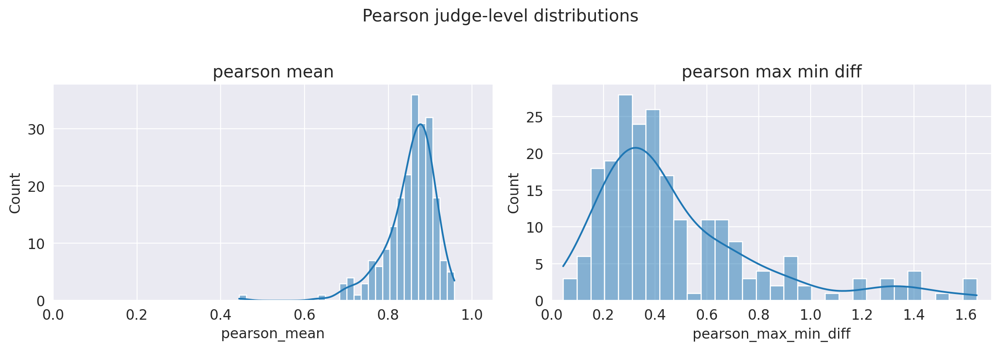

(<Figure size 1200x400 with 2 Axes>,
 array([<Axes: title={'center': 'pearson mean'}, xlabel='pearson_mean', ylabel='Count'>,
        <Axes: title={'center': 'pearson max min diff'}, xlabel='pearson_max_min_diff', ylabel='Count'>],
       dtype=object))

In [118]:
plot_two_histplots(
    node_df,
    col_left="pearson_mean",
    col_right="pearson_max_min_diff",
    title="Pearson judge-level distributions",
    bins=30,
    kde=True,
    xlim_left=(0, 1.05),
    xlim_right=(0.0, 1.7),
    fig_name="figures/pearson_nodes_description.png"
)

# **Dataset description**

## 0. Import dataset and transform columns

In [5]:
path_wide = '/home/frantsuaza/Documents/Science/SportLab/collusion_judges/data/processed/wide_dataset.xlsx'
path_long = '/home/frantsuaza/Documents/Science/SportLab/collusion_judges/data/processed/long_dataset.xlsx'

wide_dataset = pd.read_excel(path_wide,  index_col=0)
long_dataset = pd.read_excel(path_long,  index_col=0)

wide_dataset.head()

,athlete_country,year,stage,sex,program,base_score,judge_1_tech_place,judge_2_tech_place,judge_3_tech_place,judge_4_tech_place,...,judge_8_CPI_score,judge_8_CPI_rank,judge_8_CPI_region,judge_8_country_match,judge_8_component_score_norm,judge_9_CPI_score,judge_9_CPI_rank,judge_9_CPI_region,judge_9_country_match,judge_9_component_score_norm
0,JPN,2022,GP Skate America,Mens,ShortProgram,44.45,1,1,1,1,...,73,18,AP,1,24.754491,75.0,13.0,AP,0,24.754491
1,KOR,2022,GP Skate America,Mens,ShortProgram,42.90,2,2,2,2,...,73,18,AP,0,26.000000,75.0,13.0,AP,0,28.005988
2,ITA,2022,GP Skate America,Mens,ShortProgram,43.11,3,3,3,3,...,73,18,AP,0,22.754491,75.0,13.0,AP,0,26.748503
3,USA,2022,GP Skate America,Mens,ShortProgram,47.10,4,4,4,4,...,73,18,AP,0,23.748503,75.0,13.0,AP,0,26.497006
4,CAN,2022,GP Skate America,Mens,ShortProgram,36.20,8,8,7,8,...,73,18,AP,0,22.005988,75.0,13.0,AP,0,26.000000


In [93]:
del wide_dataset, long_dataset

In [6]:
rename = {'Mens': 'men', 'Womens' : 'women', 'Dance' : 'ice_dance', 'Pairs' : 'pairs'}
wide_dataset['sex'] = wide_dataset['sex'].apply(lambda x: rename[x])

## 1. Descriptive statistics

In [8]:
#long_dataset.groupby(['event', 'category']).count()
# long_dataset[long_dataset['program_numeric'] == 0].groupby(['event', 'category']).count()
#long_dataset[long_dataset['category'] == 'ice_dance'].groupby('judge_country').count()

In [31]:
long_dataset.to_excel('long_dataset.xlsx', index = False)

In [65]:
wide_dataset[(wide_dataset['program_numeric'] == 0) & (wide_dataset['stage'] != 'Grand Prix Final')].groupby(['sex']).count()[['athlete_country', 'athlete_name']] / 18


,athlete_country,athlete_name
sex,,
ice_dance,9.888889,9.888889
men,11.888889,11.888889
pairs,7.722222,7.722222
women,11.944444,11.944444


In [71]:
wide_dataset[(wide_dataset['program_numeric'] == 0) & (wide_dataset['stage'] != 'Grand Prix Final')].groupby(['event'])['athlete_name'].nunique().mean() 


41.44444444444444

In [66]:
wide_dataset[(wide_dataset['program_numeric'] == 0) ].groupby(['sex']).count()[['athlete_country', 'athlete_name']] / 21


,athlete_country,athlete_name
sex,,
ice_dance,9.333333,9.333333
men,11.047619,11.047619
pairs,7.476190,7.476190
women,11.095238,11.095238


In [64]:
wide_dataset[(wide_dataset['program_numeric'] == 0) & (wide_dataset['stage'] == 'Grand Prix Final')].groupby(['sex']).count() / 3


,athlete_country,year,stage,program,base_score,judge_1_tech_place,judge_2_tech_place,judge_3_tech_place,judge_4_tech_place,judge_5_tech_place,...,judge_8_CPI_score,judge_8_CPI_rank,judge_8_CPI_region,judge_8_country_match,judge_8_component_score_norm,judge_9_CPI_score,judge_9_CPI_rank,judge_9_CPI_region,judge_9_country_match,judge_9_component_score_norm
sex,,,,,,,,,,,,,,,,,,,,,
ice_dance,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,...,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0
men,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,...,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0
pairs,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,...,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0
women,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,...,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0


In [73]:
list(wide_dataset.columns)

['athlete_country',
 'year',
 'stage',
 'sex',
 'program',
 'base_score',
 'judge_1_tech_place',
 'judge_2_tech_place',
 'judge_3_tech_place',
 'judge_4_tech_place',
 'judge_5_tech_place',
 'judge_6_tech_place',
 'judge_7_tech_place',
 'judge_8_tech_place',
 'judge_9_tech_place',
 'judge_1_tech_score',
 'judge_2_tech_score',
 'judge_3_tech_score',
 'judge_4_tech_score',
 'judge_5_tech_score',
 'judge_6_tech_score',
 'judge_7_tech_score',
 'judge_8_tech_score',
 'judge_9_tech_score',
 'judge_1_component_place',
 'judge_2_component_place',
 'judge_3_component_place',
 'judge_4_component_place',
 'judge_5_component_place',
 'judge_6_component_place',
 'judge_7_component_place',
 'judge_8_component_place',
 'judge_9_component_place',
 'judge_1_component_score',
 'judge_2_component_score',
 'judge_3_component_score',
 'judge_4_component_score',
 'judge_5_component_score',
 'judge_6_component_score',
 'judge_7_component_score',
 'judge_8_component_score',
 'judge_9_component_score',
 'judge_

## 2. Distributions

### 2.1. Make corr dataset

In [11]:
def compute_pairwise_judge_corrs(sub: pd.DataFrame,
                                score_col: str,
                                method: str = "pearson",
                                min_common: int = 3):
    """
    sub: long-format subset for ONE event × category × program
    score_col: 'judge_component_score_norm' or 'judge_GOE'
    Returns: list of pairwise correlations (upper triangle) for this subset.
    """

    # Wide matrix: rows = athletes, cols = judges
    wide = sub.pivot_table(
        index="athlete_name",
        columns="judge_name",
        values=score_col,
        aggfunc="mean"
    )

    # remove judges with all missing
    wide = wide.dropna(axis=1, how="all")

    if wide.shape[1] < 2:
        return []

    corr_mat = wide.corr(method=method, min_periods=min_common)

    # Extract upper triangle correlations (exclude diagonal)
    cols = corr_mat.columns
    vals = []
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            r = corr_mat.iloc[i, j]
            if pd.notna(r):
                vals.append(float(r))

    return vals


In [12]:
def build_judge_correlation_dataset(long_df: pd.DataFrame,
                                    exclude_stage: str = "Grand Prix Final",
                                    score_cols=("judge_component_score_norm", "judge_GOE"),
                                    corr_methods=("pearson", "spearman", "kendall"),
                                    min_common: int = 3):
    """
    Returns a tidy df with one row per pairwise correlation value:
    event, category, program_numeric, program, score_type, corr_method, corr_value
    """

    df = long_df.copy()

    # Exclude Grand Prix Final
    if "stage" in df.columns:
        df = df[df["stage"] != exclude_stage]

    # Ensure categories are consistent naming
    # (adjust mapping if your data uses different strings)
    # Example: normalize to: women, men, pairs, ice_dance
    if "category" in df.columns:
        df["category"] = df["category"].str.strip().str.lower()

    # If you use numeric 'type' instead, map it:
    # 0=Women, 1=Men, 2=Pairs, 3=Ice Dance
    if "category" not in df.columns and "type" in df.columns:
        type_map = {0: "women", 1: "men", 2: "pairs", 3: "ice_dance"}
        df["category"] = df["type"].map(type_map)

    # Derive readable program label if needed
    if "program" not in df.columns and "program_numeric" in df.columns:
        df["program"] = df["program_numeric"].map({0: "short", 1: "free"})

    # iterate
    rows = []

    events = sorted(df["event"].dropna().unique())
    for event in events:
        df_e = df[df["event"] == event]

        for cat in sorted(df_e["category"].dropna().unique()):
            df_ec = df_e[df_e["category"] == cat]

            for prog in sorted(df_ec["program_numeric"].dropna().unique()):
                df_ecp = df_ec[df_ec["program_numeric"] == prog]

                # compute correlations for each score and method
                for score_col in score_cols:
                    if score_col not in df_ecp.columns:
                        continue

                    for method in corr_methods:
                        vals = compute_pairwise_judge_corrs(
                            df_ecp, score_col=score_col, method=method, min_common=min_common
                        )

                        for v in vals:
                            rows.append({
                                "event": event,
                                "category": cat,
                                "program_numeric": int(prog),
                                "program": df_ecp["program"].iloc[0] if "program" in df_ecp.columns else prog,
                                "score_type": score_col,
                                "corr_method": method,
                                "corr_value": v
                            })

    return pd.DataFrame(rows)


### 2.2. Make plots

#### NEW code

In [19]:
CATEGORY_ORDER = ("women", "men", "pairs", "ice_dance")
CATEGORY_LABELS = {
    "women": "Women",
    "men": "Men",
    "pairs": "Pairs",
    "ice_dance": "Ice dance",
}

SCORE_ORDER = ("judge_component_score_norm", "judge_GOE")
SCORE_LABELS = {
    "judge_component_score_norm": "Normalized components",
    "judge_GOE": "GOE (Tech score)",
}

In [27]:
def _slug(s: str) -> str:
    s = str(s).strip().lower()
    s = re.sub(r"[^a-z0-9_]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s


def _prepare_corr_plot_df(
    corr_df: pd.DataFrame,
    corr_method: str,
    category_order=CATEGORY_ORDER,
    score_order=SCORE_ORDER,
) -> pd.DataFrame:
    """
    Filters and prepares correlation dataframe for plotting.

    Required columns:
    category, score_type, corr_method, corr_value
    """

    required_cols = {"category", "score_type", "corr_method", "corr_value"}
    missing = required_cols - set(corr_df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    df = corr_df.copy()

    df["category"] = df["category"].astype(str).str.strip().str.lower()
    df["score_type"] = df["score_type"].astype(str).str.strip()
    df["corr_method"] = df["corr_method"].astype(str).str.strip().str.lower()

    corr_method = corr_method.lower()

    df = df[
        (df["corr_method"] == corr_method)
        & (df["category"].isin(category_order))
        & (df["score_type"].isin(score_order))
        & (df["corr_value"].notna())
    ].copy()

    df["score_type_label"] = df["score_type"].map(SCORE_LABELS)

    return df


def _set_corr_plot_formatting(
    ax,
    data: pd.DataFrame,
    corr_method: str,
    category_order=CATEGORY_ORDER,
    category_labels=CATEGORY_LABELS,
    ylim=(-1, 1.05),
    xlabel_size=15,
    ylabel_size=15,
    tick_size=12,
    legend_size=12,
):
    """
    Applies common formatting:
    - no plot title
    - category labels with n
    - large axis labels
    - y limits
    """

    counts = (
        data.groupby("category")["corr_value"]
        .count()
        .reindex(category_order, fill_value=0)
    )

    xtick_labels = [
        f"{category_labels.get(cat, cat)}\n(n={counts.loc[cat]})"
        for cat in category_order
    ]

    ax.set_xticklabels(xtick_labels, fontsize=tick_size)
    ax.tick_params(axis="y", labelsize=tick_size)

    method_label = corr_method.capitalize()
    ax.set_xlabel("Skater category", fontsize=xlabel_size)
    ax.set_ylabel(f"{method_label} correlation", fontsize=ylabel_size)

    ax.set_ylim(*ylim)
    ax.set_title("")

    legend = ax.legend(
        title="Score type",
        fontsize=legend_size,
        title_fontsize=legend_size,
        frameon=False,
        loc="best",
    )

    return ax


def plot_corr_boxplot(
    corr_df: pd.DataFrame,
    corr_method: str,
    out_dir=CORR_PATH,
    x: str = "category",
    hue: str = "score_type",
    category_order=CATEGORY_ORDER,
    score_order=SCORE_ORDER,
    figsize=(12, 6),
    ylim=(-1, 1.05),
    dpi=300,
    save=True,
    show=True,
):
    """
    Boxplot of judge-pair correlations by category.

    One figure for one correlation method:
    x = category
    hue = score_type
    y = corr_value
    """

    data = _prepare_corr_plot_df(
        corr_df=corr_df,
        corr_method=corr_method,
        category_order=category_order,
        score_order=score_order,
    )

    if data.empty:
        print(f"[WARN] No data for corr_method={corr_method}")
        return None

    fig, ax = plt.subplots(figsize=figsize)

    sns.boxplot(
        data=data,
        x=x,
        y="corr_value",
        hue="score_type_label",
        order=category_order,
        hue_order=[SCORE_LABELS[s] for s in score_order],
        ax=ax,
        width=0.7,
        showfliers=True,
    )

    _set_corr_plot_formatting(
        ax=ax,
        data=data,
        corr_method=corr_method,
        category_order=category_order,
        ylim=ylim,
    )

    plt.tight_layout()

    if save:
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)

        filename = f"box_{_slug(corr_method)}_{_slug(x)}_{_slug(hue)}.png"
        savepath = out_dir / filename

        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
        print(f"[SAVED] {savepath}")

    if show:
        plt.show()

    plt.close(fig)
    return fig, ax


def plot_corr_violinplot(
    corr_df: pd.DataFrame,
    corr_method: str,
    out_dir=CORR_PATH,
    x: str = "category",
    hue: str = "score_type",
    category_order=CATEGORY_ORDER,
    score_order=SCORE_ORDER,
    figsize=(12, 6),
    ylim=(-1, 1.05),
    dpi=300,
    save=True,
    show=True,
):
    """
    Violinplot of judge-pair correlations by category.

    One figure for one correlation method:
    x = category
    hue = score_type
    y = corr_value
    """

    data = _prepare_corr_plot_df(
        corr_df=corr_df,
        corr_method=corr_method,
        category_order=category_order,
        score_order=score_order,
    )

    if data.empty:
        print(f"[WARN] No data for corr_method={corr_method}")
        return None

    fig, ax = plt.subplots(figsize=figsize)

    sns.violinplot(
        data=data,
        x=x,
        y="corr_value",
        hue="score_type_label",
        order=category_order,
        hue_order=[SCORE_LABELS[s] for s in score_order],
        ax=ax,
        cut=0,
        inner="box",
        linewidth=1,
        density_norm="width",  # для seaborn >= 0.13
        dodge=True,
    )

    _set_corr_plot_formatting(
        ax=ax,
        data=data,
        corr_method=corr_method,
        category_order=category_order,
        ylim=ylim,
    )

    plt.tight_layout()

    if save:
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)

        filename = f"violin_{_slug(corr_method)}_{_slug(x)}_{_slug(hue)}.png"
        savepath = out_dir / filename

        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
        print(f"[SAVED] {savepath}")

    if show:
        plt.show()

    plt.close(fig)
    return fig, ax

#### Old code

In [13]:
def plot_5box_by_category(
    df: pd.DataFrame,
    title: str,
    category_order=("women", "men", "pairs", "ice_dance"),
    figsize=(16, 5),
    ylim=(-1, 1),
    show_n=True
):
    """
    Creates 5 boxplots in one row:
      [Total pooled] + [Women] + [Men] + [Pairs] + [Ice Dance]
    df must contain: category, corr_value
    """
    if df.empty:
        print(f"[WARN] Empty df for: {title}")
        return

    fig, axes = plt.subplots(1, 5, figsize=figsize, sharey=True)

    # --- Total pooled
    sns.boxplot(y=df["corr_value"], ax=axes[0])
    n_total = df["corr_value"].notna().sum()
    axes[0].set_title(f"Total" + (f"\n(n={n_total})" if show_n else ""))
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Correlation")
    axes[0].set_ylim(*ylim)

    # --- By category
    for i, cat in enumerate(category_order, start=1):
        d = df[df["category"] == cat]
        n_cat = d["corr_value"].notna().sum()

        if d.empty:
            axes[i].set_title(f"{cat}\n(no data)")
            axes[i].set_xticks([])
            axes[i].set_xlabel("")
            axes[i].set_ylim(*ylim)
            continue

        sns.boxplot(y=d["corr_value"], ax=axes[i])
        axes[i].set_title(f"{cat}" + (f"\n(n={n_cat})" if show_n else ""))
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")
        axes[i].set_ylim(*ylim)

    fig.suptitle(title, y=1.05)
    plt.tight_layout()
    plt.show()


In [14]:
def plot_corr_overview_3programs(
    corr_df: pd.DataFrame,
    score_type: str,
    corr_method: str,
    category_order=("women", "men", "pairs", "ice_dance"),
    figsize=(16, 5),
    ylim=(-1, 1)
):
    """
    For a given score_type and corr_method, makes 3 figures:
      - short only (program_numeric == 0)
      - free only  (program_numeric == 1)
      - all pooled (no filter by program_numeric)
    """

    base = corr_df[
        (corr_df["score_type"] == score_type) &
        (corr_df["corr_method"] == corr_method)
    ].copy()

    if base.empty:
        print(f"[WARN] No data for score_type={score_type}, corr_method={corr_method}")
        return

    # --- Short
    df_short = base[base["program_numeric"] == 0]
    plot_5box_by_category(
        df_short,
        title=f"{corr_method.upper()} | {score_type} | Short program",
        category_order=category_order,
        figsize=figsize,
        ylim=ylim
    )

    # --- Free
    df_free = base[base["program_numeric"] == 1]
    plot_5box_by_category(
        df_free,
        title=f"{corr_method.upper()} | {score_type} | Free program",
        category_order=category_order,
        figsize=figsize,
        ylim=ylim
    )

    # --- All pooled (short + free together)
    plot_5box_by_category(
        base,
        title=f"{corr_method.upper()} | {score_type} | All programs pooled",
        category_order=category_order,
        figsize=figsize,
        ylim=ylim
    )


In [85]:
def plot_5box_by_category_hue(
    df: pd.DataFrame,
    title: str,
    category_order=("women", "men", "pairs", "ice_dance"),
    score_order=("judge_component_score_norm", "judge_GOE"),
    figsize=(18, 5),
    ylim=(-1, 1),
    show_n=True
):
    """
    5 panels (Total + 4 categories).
    In each panel: boxplot of corr_value with hue='score_type' (2 boxes).
    """
    if df.empty:
        print(f"[WARN] Empty df for: {title}")
        return

    fig, axes = plt.subplots(1, 5, figsize=figsize, sharey=True)

    # --- TOTAL pooled
    n_total = df["corr_value"].notna().sum()
    sns.boxplot(
        data=df, x="score_type", y="corr_value",
        order=score_order, ax=axes[0]
    )
    axes[0].set_title("Total" + (f"\n(n={n_total})" if show_n else ""))
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Correlation")
    axes[0].set_ylim(*ylim)

    # --- Categories
    for i, cat in enumerate(category_order, start=1):
        d = df[df["category"] == cat]
        n_cat = d["corr_value"].notna().sum()

        if d.empty:
            axes[i].set_title(f"{cat}\n(no data)")
            axes[i].set_xticks([])
            axes[i].set_xlabel("")
            axes[i].set_ylim(*ylim)
            continue

        sns.boxplot(
            data=d, x="score_type", y="corr_value",
            order=score_order, ax=axes[i]
        )
        axes[i].set_title(f"{cat}" + (f"\n(n={n_cat})" if show_n else ""))
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")
        axes[i].set_ylim(*ylim)

    # Cleaner x tick labels
    for ax in axes:
        ax.set_xticklabels(["Components", "GOE"], rotation=0)

    fig.suptitle(title, y=1.05)
    plt.tight_layout()
    plt.show()


In [86]:
def plot_corr_overview_3programs_hue(
    corr_df: pd.DataFrame,
    corr_method: str,
    score_types=("judge_component_score_norm", "judge_GOE"),
    category_order=("women", "men", "pairs", "ice_dance"),
    figsize=(18, 5),
    ylim=(-1, 1)
):
    """
    For a given corr_method, makes 3 figures:
      - short only
      - free only
      - all pooled
    Each figure: 5 panels; each panel has 2 boxplots (Components vs GOE).
    """
    base = corr_df[
        (corr_df["corr_method"] == corr_method) &
        (corr_df["score_type"].isin(score_types))
    ].copy()

    if base.empty:
        print(f"[WARN] No data for corr_method={corr_method} and score_types={score_types}")
        return

    # SHORT
    df_short = base[base["program_numeric"] == 0]
    plot_5box_by_category_hue(
        df_short,
        title=f"{corr_method.upper()} | Short program",
        category_order=category_order,
        score_order=score_types,
        figsize=figsize,
        ylim=ylim
    )

    # FREE
    df_free = base[base["program_numeric"] == 1]
    plot_5box_by_category_hue(
        df_free,
        title=f"{corr_method.upper()} | Free program",
        category_order=category_order,
        score_order=score_types,
        figsize=figsize,
        ylim=ylim
    )

    # ALL pooled
    plot_5box_by_category_hue(
        base,
        title=f"{corr_method.upper()} | All programs pooled",
        category_order=category_order,
        score_order=score_types,
        figsize=figsize,
        ylim=ylim
    )


/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_pearson_short_components_vs_goe.png


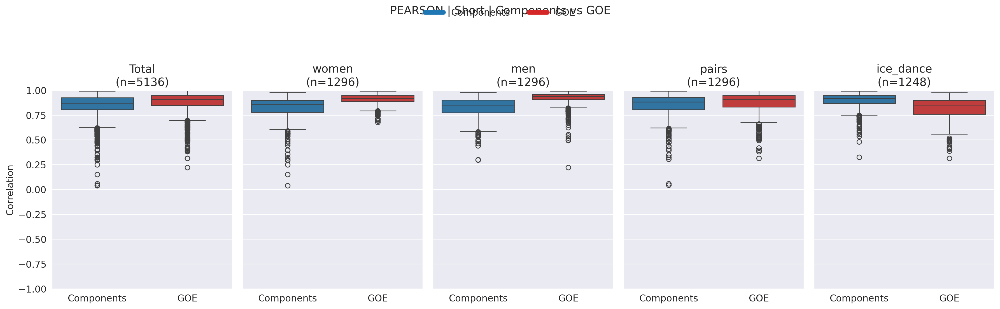

/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_pearson_free_components_vs_goe.png


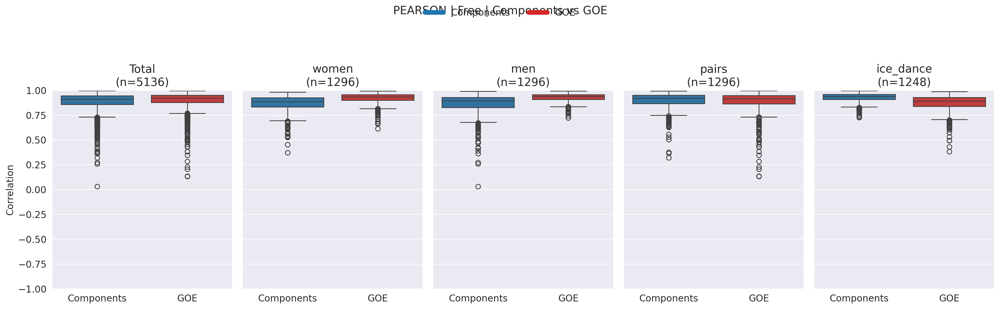

/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_pearson_all_components_vs_goe.png


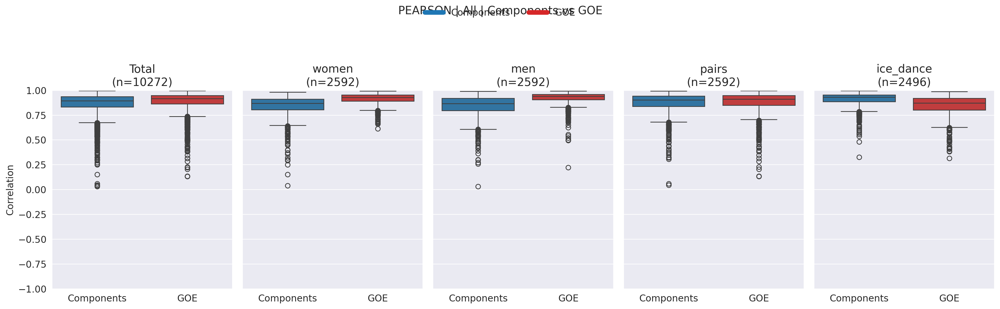

/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_spearman_short_components_vs_goe.png


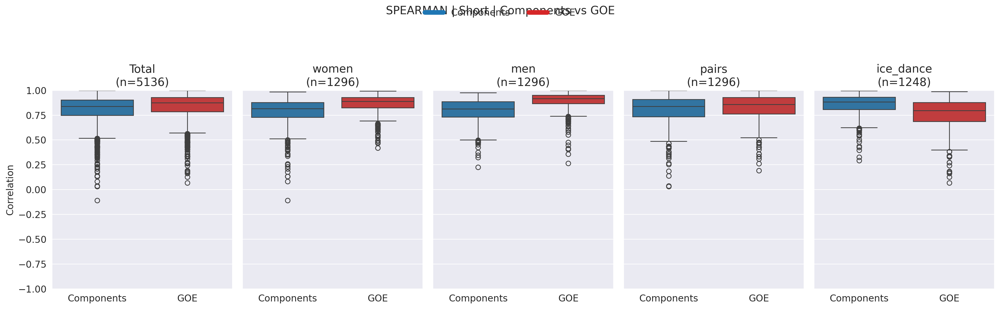

/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_spearman_free_components_vs_goe.png


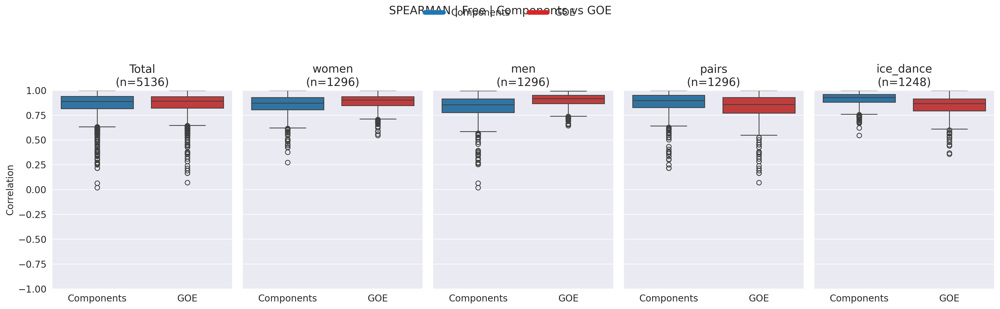

/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_spearman_all_components_vs_goe.png


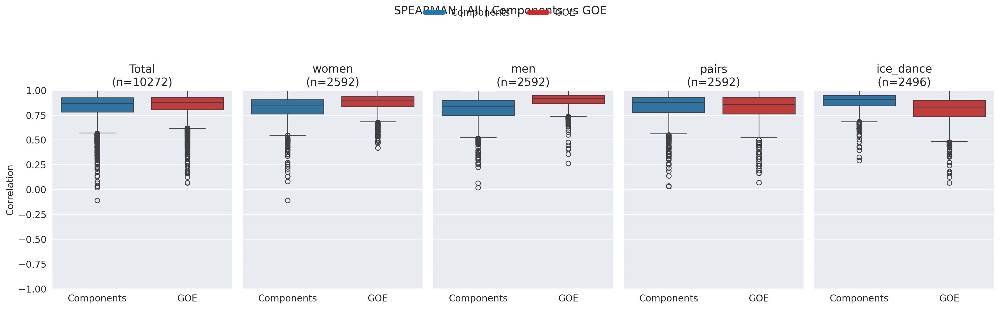

/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_kendall_short_components_vs_goe.png


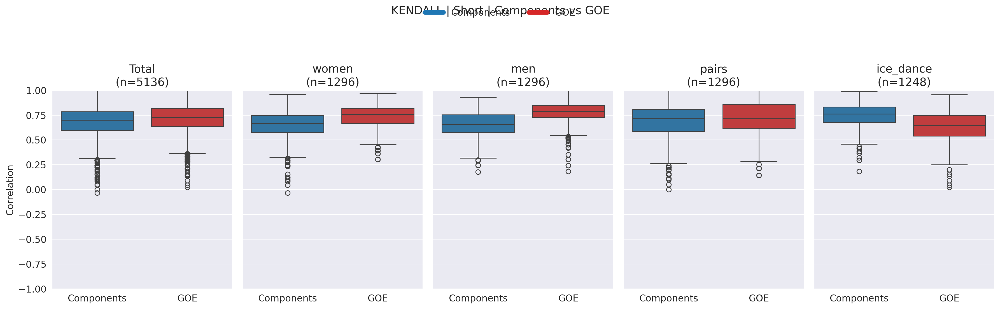

/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_kendall_free_components_vs_goe.png


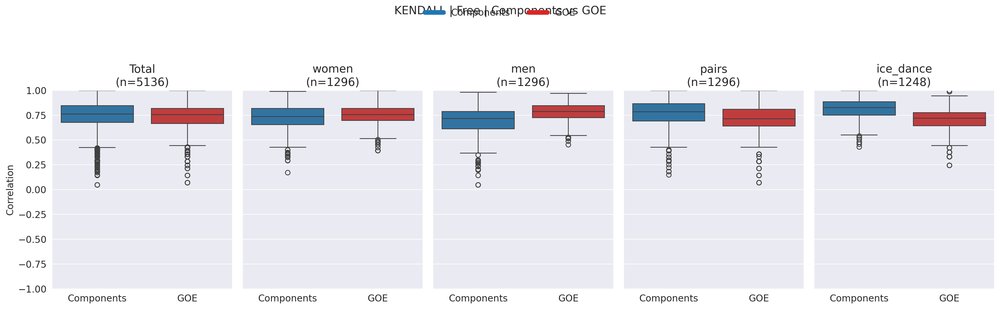

/tmp/ipykernel_71812/1262338099.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/1262338099.py:72: FutureWarning

[SAVED] figures/corr_boxplots/box_kendall_all_components_vs_goe.png


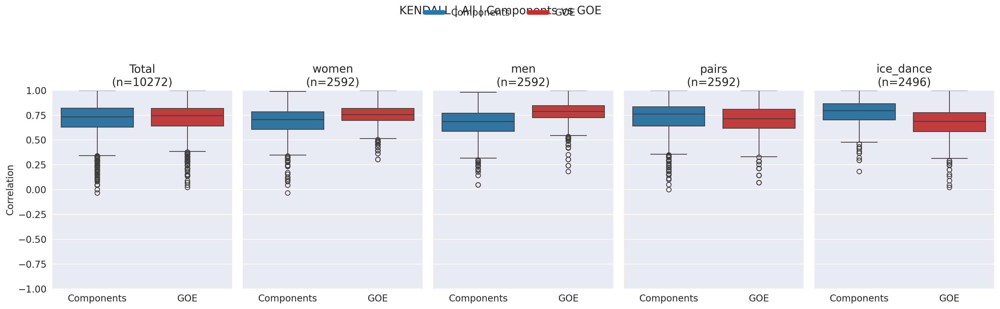

In [88]:
# --- 1) Helper to make safe filenames
def _slug(s: str) -> str:
    s = s.strip().lower()
    s = re.sub(r"[^a-z0-9_]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s

# --- 2) 5-panel plot with fixed colors for score types + saving
def plot_5box_by_category_two_scores(
    df: pd.DataFrame,
    title: str,
    category_order=("women", "men", "pairs", "ice_dance"),
    score_order=("judge_component_score_norm", "judge_GOE"),
    score_labels=("Components", "GOE"),
    palette=None,
    figsize=(18, 5),
    ylim=(-1, 1),
    show_n=True,
    savepath=None,   # if provided, saves figure
    dpi=200
):
    """
    5 panels (Total + 4 categories).
    In each panel: two boxplots (Components vs GOE) with fixed colors.
    """

    if df.empty:
        print(f"[WARN] Empty df for: {title}")
        return

    # Default palette (Components vs GOE)
    if palette is None:
        palette = {
            "judge_component_score_norm": "#4C72B0",  # blue
            "judge_GOE": "#DD8452",                  # orange
        }

    fig, axes = plt.subplots(1, 5, figsize=figsize, sharey=True)

    # --- TOTAL pooled
    n_total = df["corr_value"].notna().sum()
    sns.boxplot(
        data=df,
        x="score_type", y="corr_value",
        order=score_order,
        palette=palette,
        ax=axes[0]
    )
    axes[0].set_title("Total" + (f"\n(n={n_total})" if show_n else ""))
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Correlation")
    axes[0].set_ylim(*ylim)

    # --- Categories
    for i, cat in enumerate(category_order, start=1):
        d = df[df["category"] == cat]
        n_cat = d["corr_value"].notna().sum()

        if d.empty:
            axes[i].set_title(f"{cat}\n(no data)")
            axes[i].set_xticks([])
            axes[i].set_xlabel("")
            axes[i].set_ylim(*ylim)
            continue

        sns.boxplot(
            data=d,
            x="score_type", y="corr_value",
            order=score_order,
            palette=palette,
            ax=axes[i]
        )
        axes[i].set_title(f"{cat}" + (f"\n(n={n_cat})" if show_n else ""))
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")
        axes[i].set_ylim(*ylim)

    # --- Clean x tick labels
    for ax in axes:
        ax.set_xticklabels(list(score_labels), rotation=0)

    # --- Single legend (remove duplicates)
    # seaborn creates legend per axis sometimes; easiest is to remove and add one global
    for ax in axes:
        leg = ax.get_legend()
        if leg is not None:
            leg.remove()

    # Create global legend using dummy handles
    handles = [
        plt.Line2D([0], [0], color=palette[score_order[0]], lw=6),
        plt.Line2D([0], [0], color=palette[score_order[1]], lw=6),
    ]
    fig.legend(handles, list(score_labels), loc="upper center", ncol=2, frameon=False)

    fig.suptitle(title, y=1.10)
    plt.tight_layout()

    # --- Save
    if savepath is not None:
        os.makedirs(os.path.dirname(savepath), exist_ok=True)
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
        print(f"[SAVED] {savepath}")

    plt.show()
    plt.close(fig)

# --- 3) Plot 3 program scopes for a given corr_method and save figs
def plot_corr_overview_3programs_two_scores(
    corr_df: pd.DataFrame,
    corr_method: str,
    out_dir: str,
    score_types=("judge_component_score_norm", "judge_GOE"),
    category_order=("women", "men", "pairs", "ice_dance"),
    palette=None,
    figsize=(18, 5),
    ylim=(-1, 1),
    dpi=200
):
    base = corr_df[
        (corr_df["corr_method"] == corr_method) &
        (corr_df["score_type"].isin(score_types))
    ].copy()

    if base.empty:
        print(f"[WARN] No data for corr_method={corr_method}")
        return

    scopes = [
        ("short", base[base["program_numeric"] == 0]),
        ("free",  base[base["program_numeric"] == 1]),
        ("all",   base),
    ]

    for scope_name, df_scope in scopes:
        title = f"{corr_method.upper()} | {scope_name.capitalize()} | Components vs GOE"
        filename = f"box_{_slug(corr_method)}_{_slug(scope_name)}_components_vs_goe.png"
        savepath = os.path.join(out_dir, filename)

        plot_5box_by_category_two_scores(
            df_scope,
            title=title,
            category_order=category_order,
            score_order=score_types,
            score_labels=("Components", "GOE"),
            palette=palette,
            figsize=figsize,
            ylim=ylim,
            savepath=savepath,
            dpi=dpi
        )



In [89]:
def _slug(s: str) -> str:
    s = s.strip().lower()
    s = re.sub(r"[^a-z0-9_]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s

def plot_corr_methods_one_fig(
    corr_df: pd.DataFrame,
    out_dir: str = "figures/corr_boxplots",
    filename: str = "box_components_vs_goe_all_programs_3corr.png",
    corr_methods=("pearson", "spearman", "kendall"),
    score_types=("judge_component_score_norm", "judge_GOE"),
    score_labels=("Components", "GOE"),
    palette=None,
    ylim=(-1, 1.05),
    figsize=(14, 5),
    dpi=250
):
    """
    One figure with 3 subplots (Pearson/Spearman/Kendall).
    Each subplot shows two boxplots (Components vs GOE).
    Uses ALL data pooled across programs and categories.
    """

    if palette is None:
        palette = {
            "judge_component_score_norm": "#1f77b4",  # blue
            "judge_GOE": "#d62728",                  # red
        }

    # filter for the two score types
    base = corr_df[corr_df["score_type"].isin(score_types)].copy()
    if base.empty:
        print("[WARN] No data after filtering by score_types.")
        return

    fig, axes = plt.subplots(1, len(corr_methods), figsize=figsize, sharey=True)

    if len(corr_methods) == 1:
        axes = [axes]

    for ax, method in zip(axes, corr_methods):
        d = base[base["corr_method"] == method]
        if d.empty:
            ax.set_title(method.upper())
            ax.text(0.5, 0.5, "no data", ha="center", va="center")
            ax.set_xticks([])
            ax.set_ylim(*ylim)
            continue

        sns.boxplot(
            data=d,
            x="score_type", y="corr_value",
            order=score_types,
            palette=palette,
            ax=ax
        )
        ax.set_title(method.upper())
        ax.set_xlabel("")
        ax.set_ylim(*ylim)

        # cleaner x labels
        ax.set_xticklabels(list(score_labels), rotation=0)

        # remove axis-level legends if any
        leg = ax.get_legend()
        if leg is not None:
            leg.remove()

    axes[0].set_ylabel("Correlation")
    for ax in axes[1:]:
        ax.set_ylabel("")

    # global legend
    handles = [
        plt.Line2D([0], [0], color=palette[score_types[0]], lw=6),
        plt.Line2D([0], [0], color=palette[score_types[1]], lw=6),
    ]
    fig.legend(handles, list(score_labels), loc="upper center", ncol=2, frameon=False)

    fig.suptitle("Judge correlation distributions: Components vs GOE (All programs pooled)", y=1.08)
    plt.tight_layout()

    # save
    os.makedirs(out_dir, exist_ok=True)
    savepath = os.path.join(out_dir, filename)
    fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    print(f"[SAVED] {savepath}")

    plt.show()
    plt.close(fig)


In [91]:
def plot_corr_methods_one_fig(
    corr_df: pd.DataFrame,
    out_dir: str = "figures/corr_boxplots",
    filename: str = "box_components_vs_goe_all_programs_3corr.png",
    corr_methods=("pearson", "spearman", "kendall"),
    score_types=("judge_component_score_norm", "judge_GOE"),
    score_labels=("Components", "GOE"),
    palette=None,
    ylim=(-0.25, 1.05),
    figsize=(15, 5),
    dpi=300,
    title="Judge correlation distributions: Components vs GOE (All programs pooled)"
):
    if palette is None:
        palette = {
            "judge_component_score_norm": "#1f77b4",  # blue
            "judge_GOE": "#d62728",                  # red
        }

    base = corr_df[corr_df["score_type"].isin(score_types)].copy()
    if base.empty:
        print("[WARN] No data after filtering by score_types.")
        return

    fig, axes = plt.subplots(1, len(corr_methods), figsize=figsize, sharey=True)
    if len(corr_methods) == 1:
        axes = [axes]

    for ax, method in zip(axes, corr_methods):
        d = base[base["corr_method"] == method]
        if d.empty:
            ax.set_title(method.upper())
            ax.text(0.5, 0.5, "no data", ha="center", va="center")
            ax.set_xticks([])
            ax.set_ylim(*ylim)
            continue

        sns.boxplot(
            data=d,
            x="score_type", y="corr_value",
            order=score_types,
            palette=palette,
            ax=ax
        )
        ax.set_title(method.upper())
        ax.set_xlabel("")
        ax.set_ylim(*ylim)
        ax.set_xticklabels(list(score_labels), rotation=0)

        leg = ax.get_legend()
        if leg is not None:
            leg.remove()

    axes[0].set_ylabel("Correlation")
    for ax in axes[1:]:
        ax.set_ylabel("")

    # --- 1) Заголовок выше
    fig.suptitle(title, y=0.99)

    # --- 2) Легенда ниже заголовка (в отдельной строке)
    handles = [
        plt.Line2D([0], [0], color=palette[score_types[0]], lw=6),
        plt.Line2D([0], [0], color=palette[score_types[1]], lw=6),
    ]
    fig.legend(
        handles, list(score_labels),
        loc="upper center",
        bbox_to_anchor=(0.5, 0.93),  # ниже заголовка
        ncol=2,
        frameon=False
    )

    # --- 3) Резервируем верхнее пространство под title+legend
    plt.tight_layout(rect=[0, 0, 1, 0.88])

    os.makedirs(out_dir, exist_ok=True)
    savepath = os.path.join(out_dir, filename)
    fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    print(f"[SAVED] {savepath}")

    plt.show()
    plt.close(fig)


### 2.3. RUN THE CODE

#### IMPORT

In [15]:
corr_df = build_judge_correlation_dataset(long_dataset, min_common=3)
corr_df.head()


,event,category,program_numeric,program,score_type,corr_method,corr_value
0,2022_GP_Espoo,ice_dance,0,RhythmDance,judge_component_score_norm,pearson,0.918347
1,2022_GP_Espoo,ice_dance,0,RhythmDance,judge_component_score_norm,pearson,0.938249
2,2022_GP_Espoo,ice_dance,0,RhythmDance,judge_component_score_norm,pearson,0.870646
3,2022_GP_Espoo,ice_dance,0,RhythmDance,judge_component_score_norm,pearson,0.978996
4,2022_GP_Espoo,ice_dance,0,RhythmDance,judge_component_score_norm,pearson,0.906520


#### Make plots

[SAVED] /home/frantsuaza/Documents/Science/SportLab/collusion_judges/reports/figures/Corr_2/box_pearson_category_score_type.png


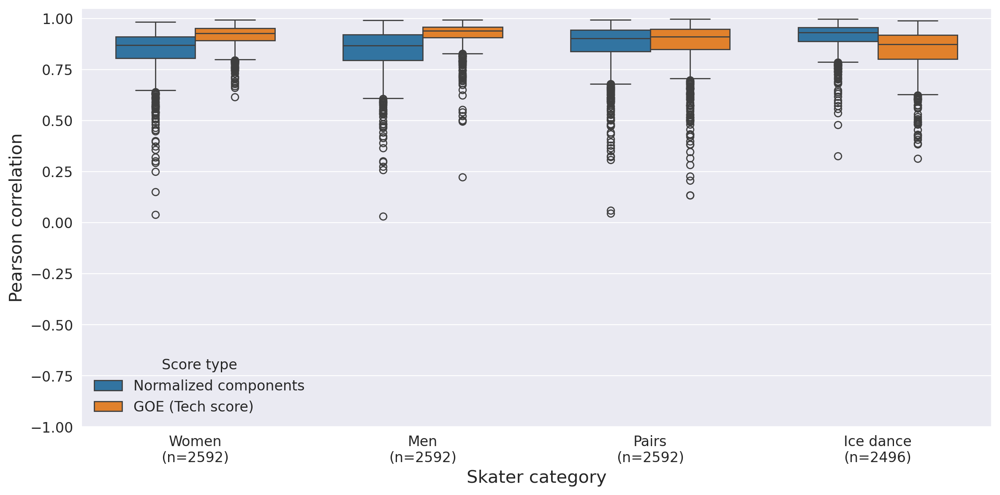

[SAVED] /home/frantsuaza/Documents/Science/SportLab/collusion_judges/reports/figures/Corr_2/violin_pearson_category_score_type.png


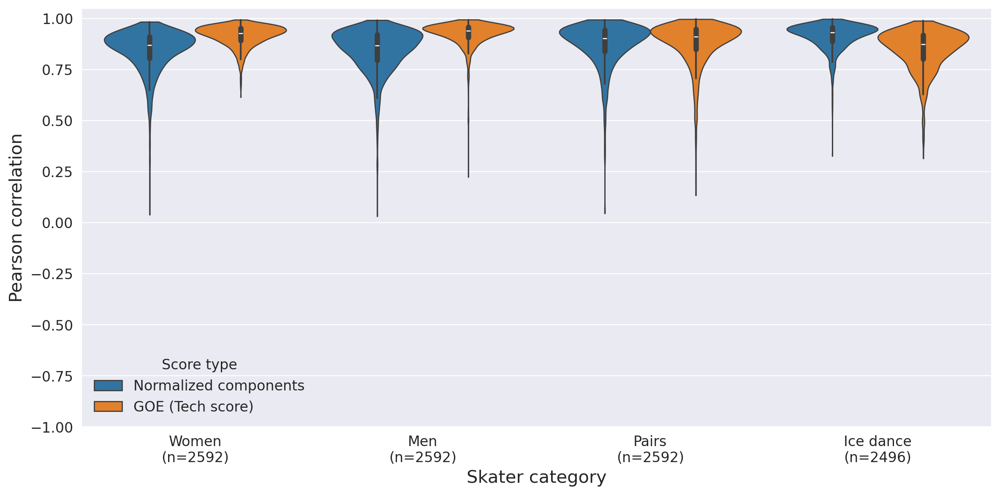

[SAVED] /home/frantsuaza/Documents/Science/SportLab/collusion_judges/reports/figures/Corr_2/box_spearman_category_score_type.png


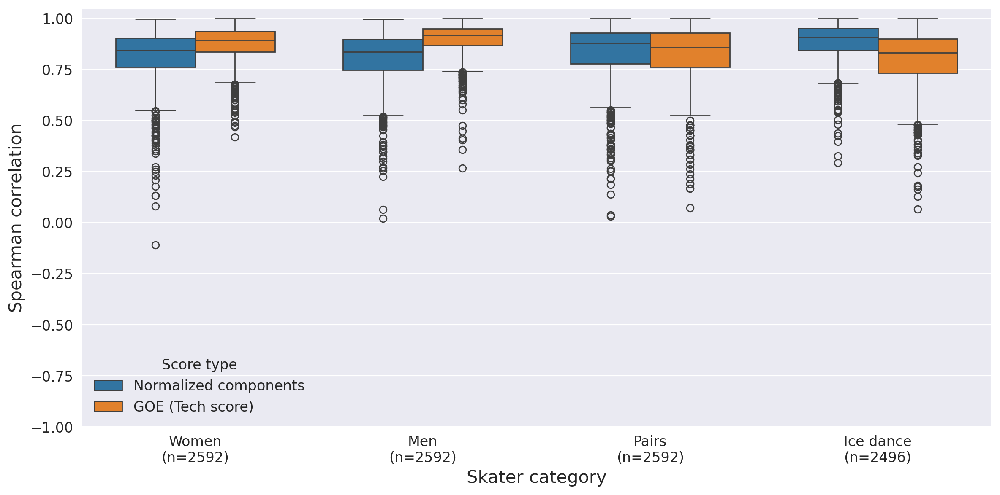

[SAVED] /home/frantsuaza/Documents/Science/SportLab/collusion_judges/reports/figures/Corr_2/violin_spearman_category_score_type.png


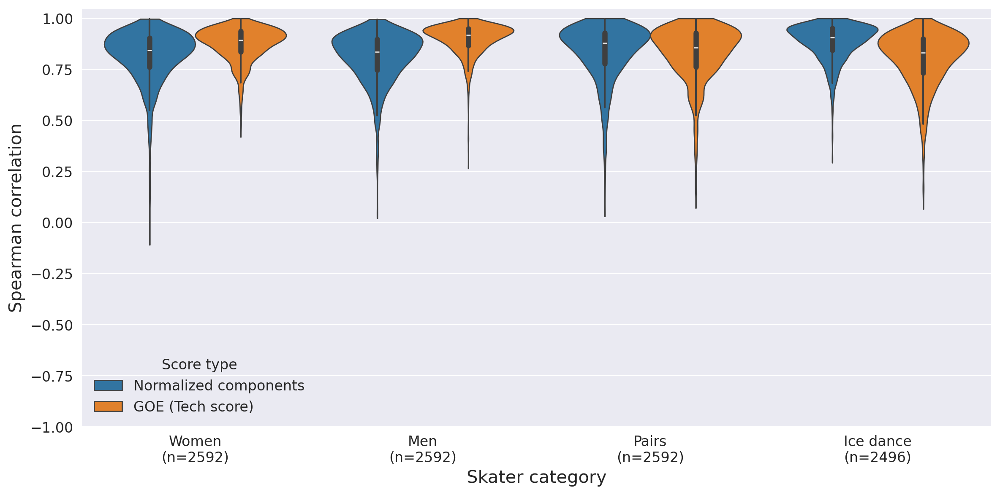

[SAVED] /home/frantsuaza/Documents/Science/SportLab/collusion_judges/reports/figures/Corr_2/box_kendall_category_score_type.png


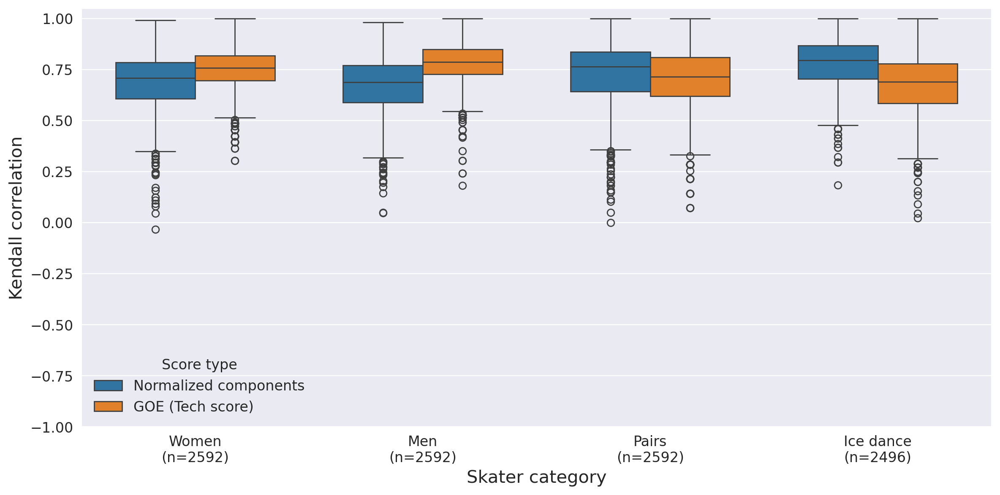

[SAVED] /home/frantsuaza/Documents/Science/SportLab/collusion_judges/reports/figures/Corr_2/violin_kendall_category_score_type.png


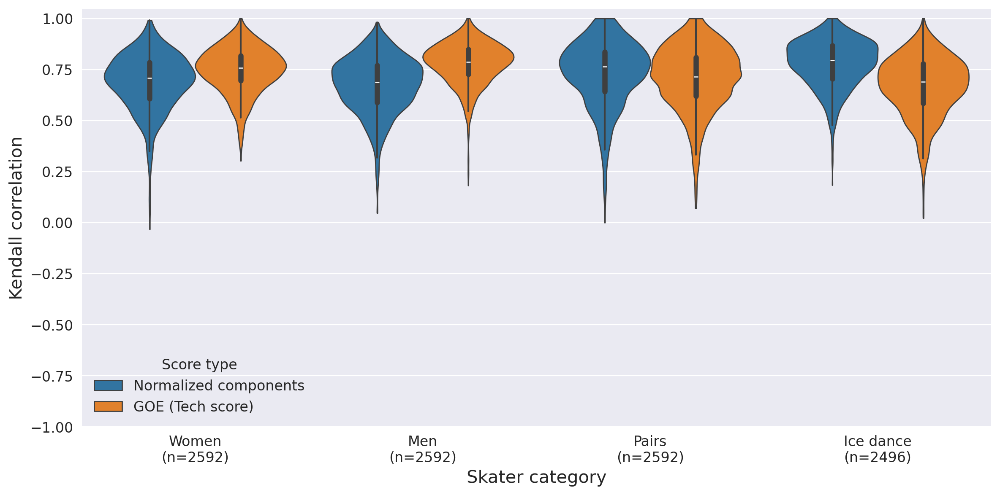

In [28]:
for method in ["pearson", "spearman", "kendall"]:
    plot_corr_boxplot(
        corr_df=corr_df,
        corr_method=method,
        out_dir=CORR_PATH,
        save=True,
        show=True,
    )

    plot_corr_violinplot(
        corr_df=corr_df,
        corr_method=method,
        out_dir=CORR_PATH,
        save=True,
        show=True,
    )

### OLD CODE

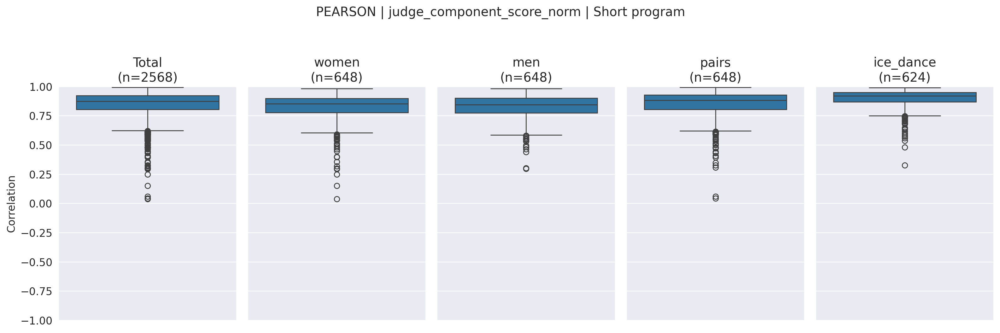

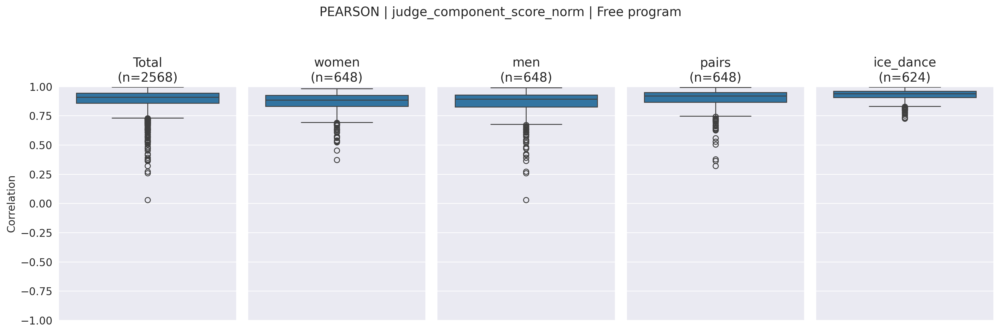

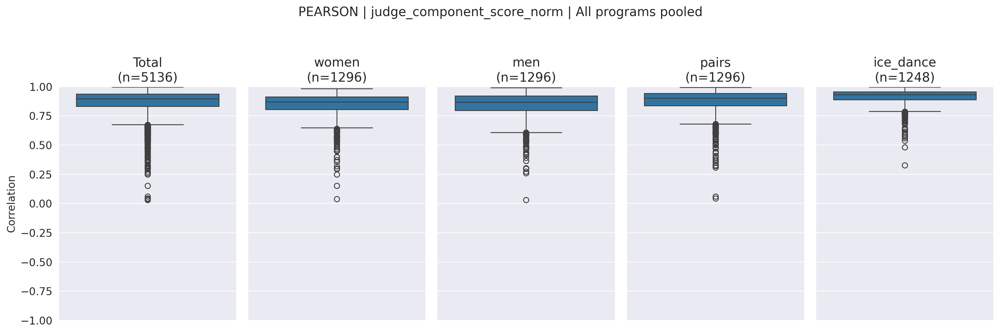

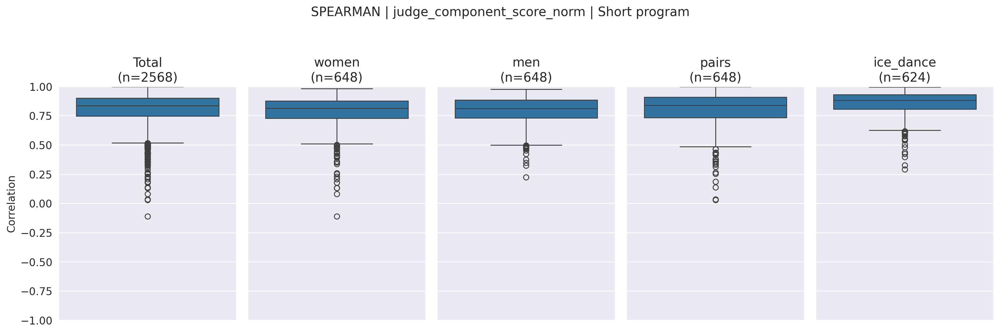

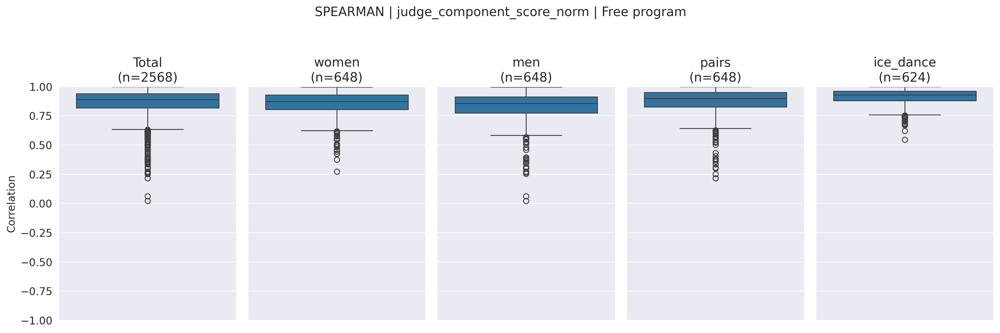

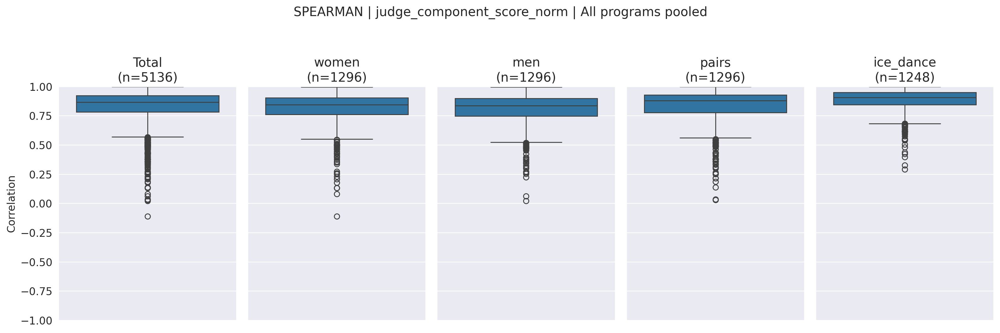

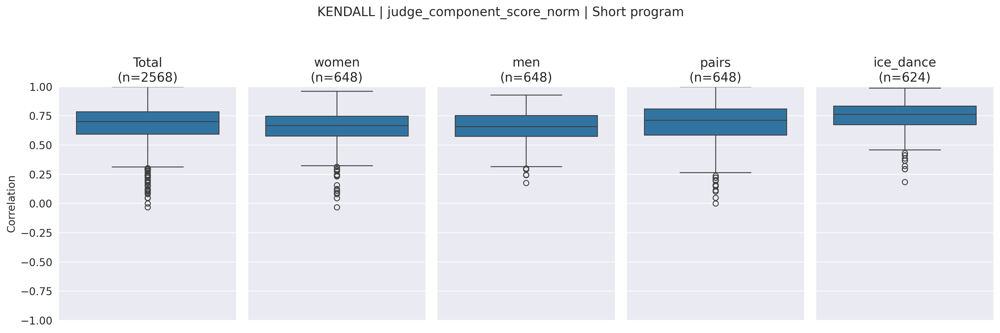

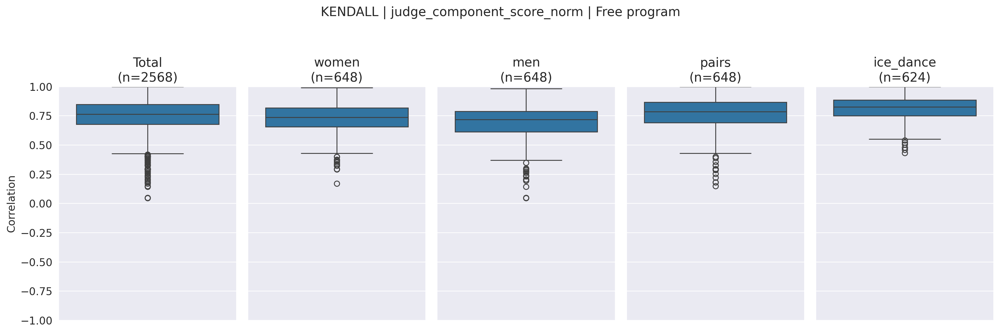

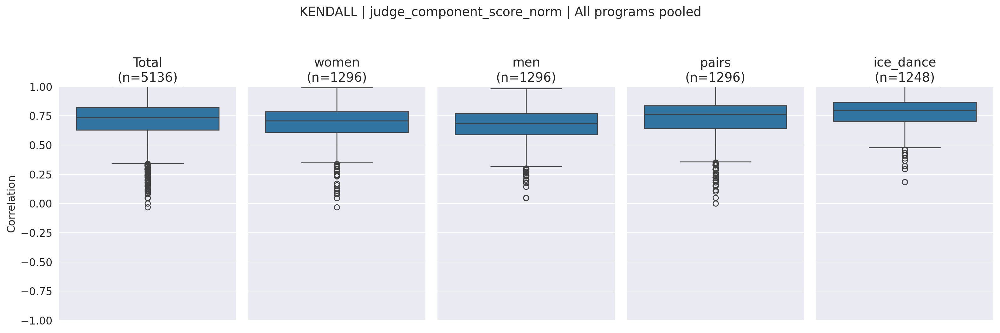

In [83]:
for method in ["pearson", "spearman", "kendall"]:
    plot_corr_overview_3programs(
        corr_df,
        score_type="judge_component_score_norm",
        corr_method=method,
        category_order=("women", "men", "pairs", "ice_dance")
    )


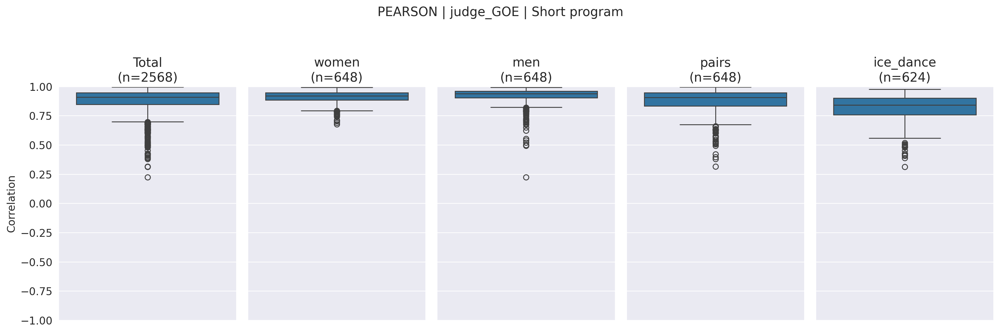

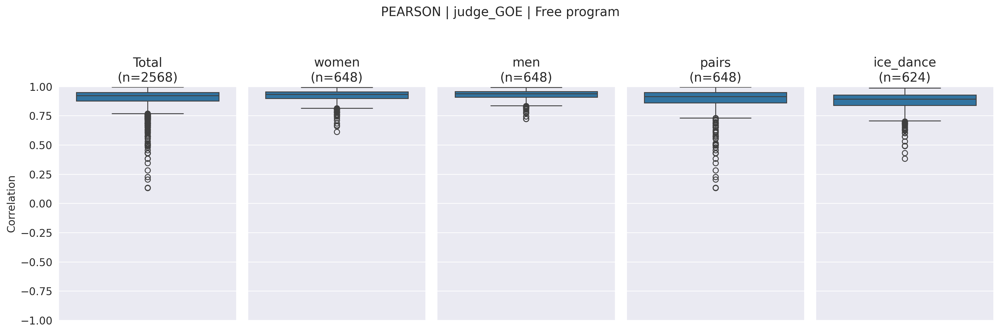

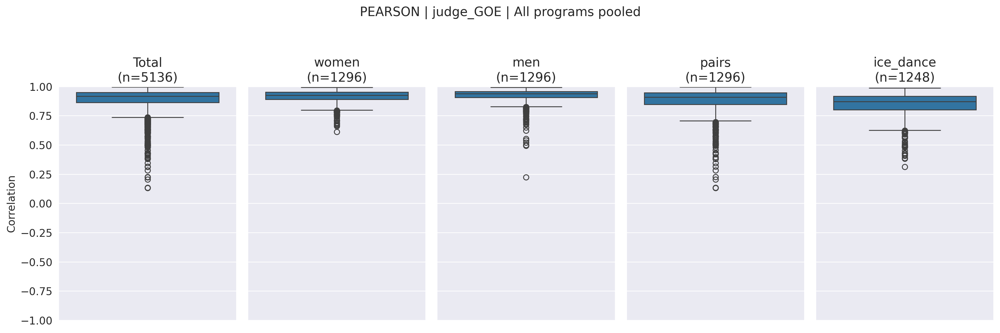

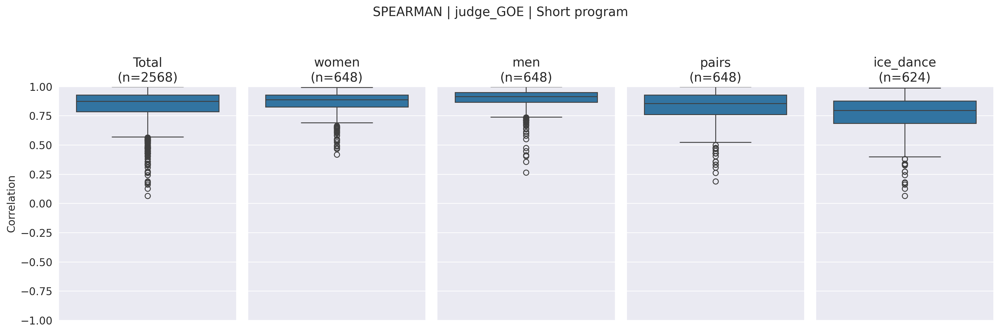

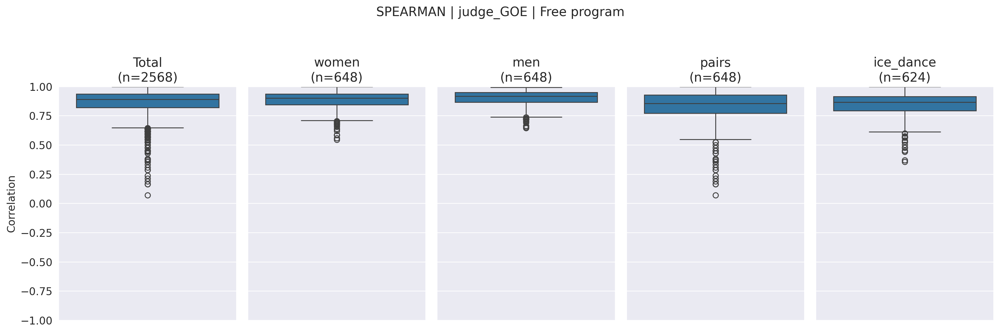

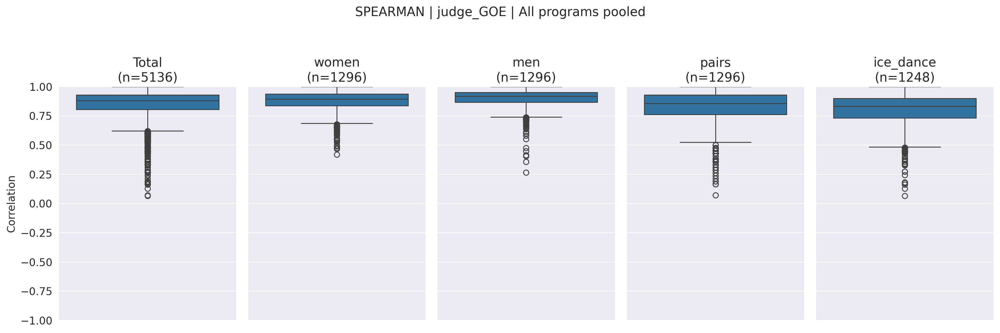

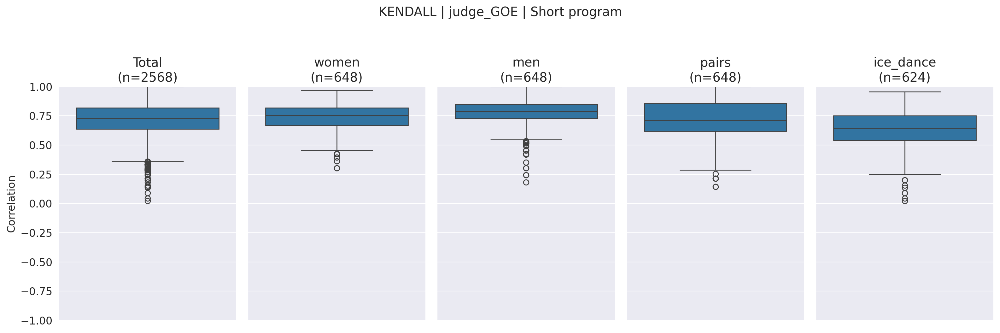

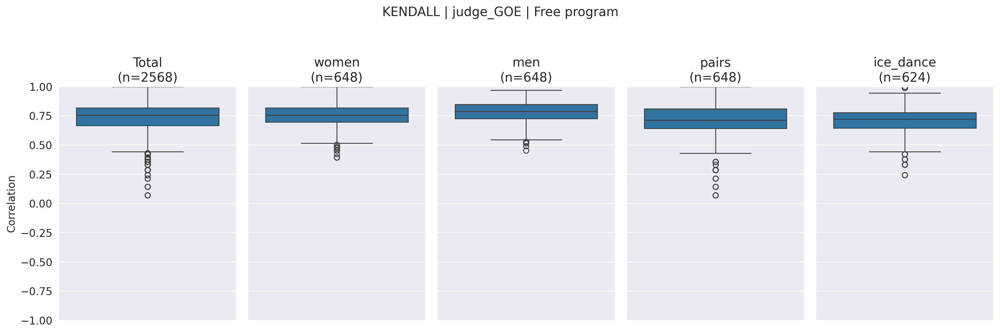

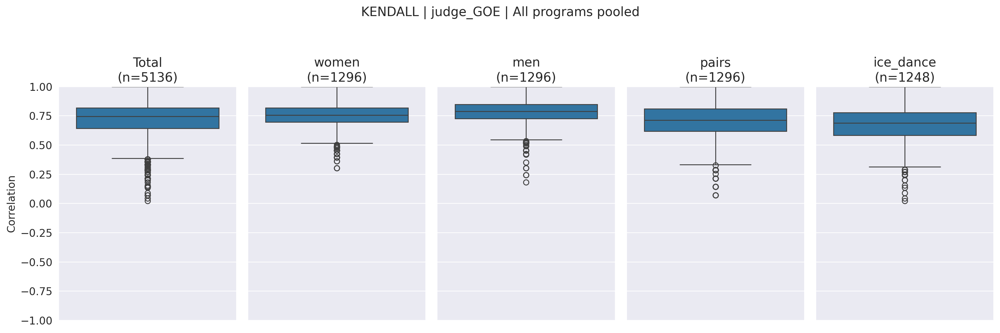

In [84]:
for method in ["pearson", "spearman", "kendall"]:
    plot_corr_overview_3programs(
        corr_df,
        score_type="judge_GOE",
        corr_method=method,
        category_order=("women", "men", "pairs", "ice_dance")
    )

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

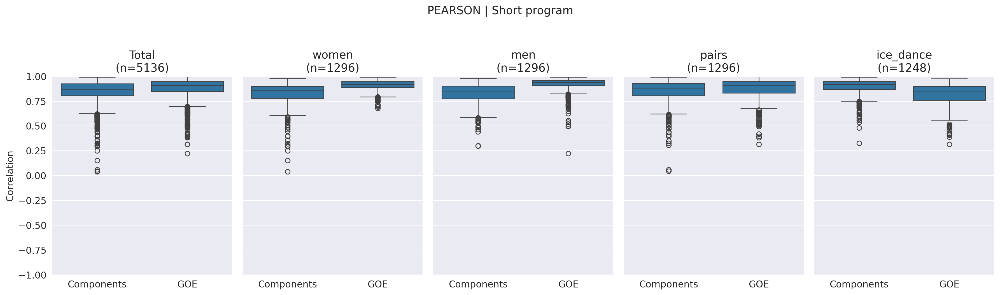

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

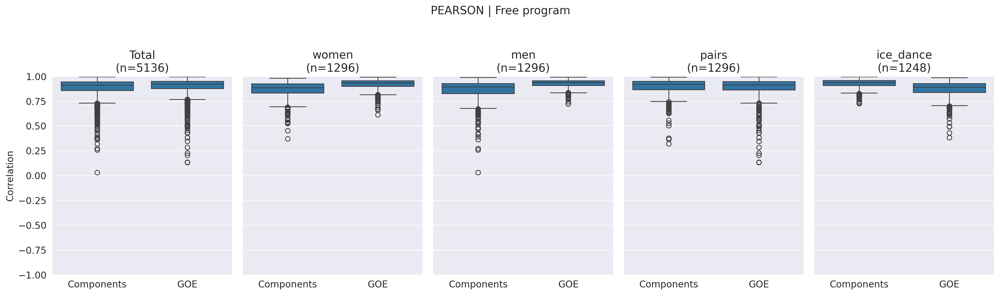

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

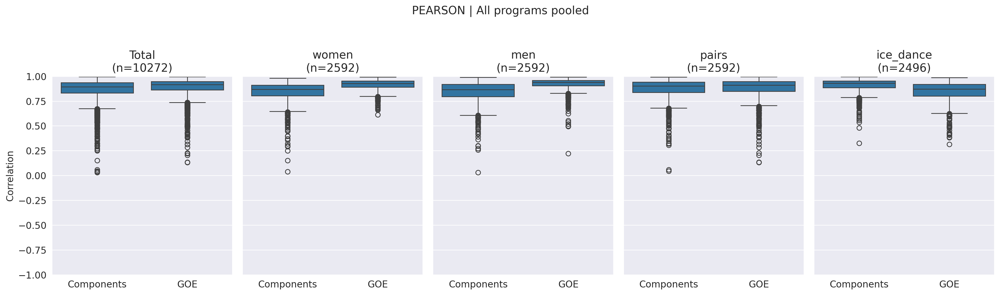

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

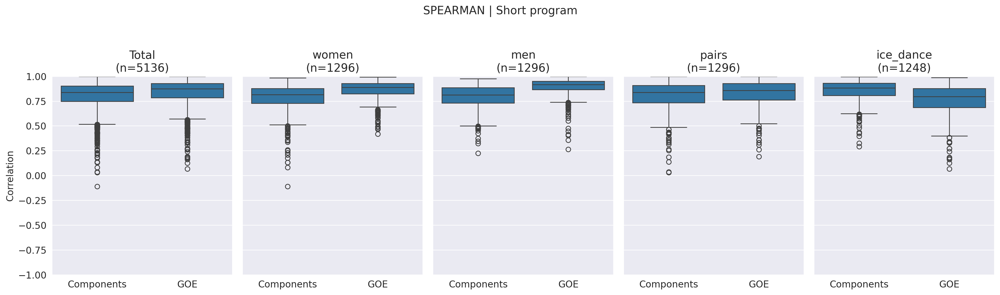

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

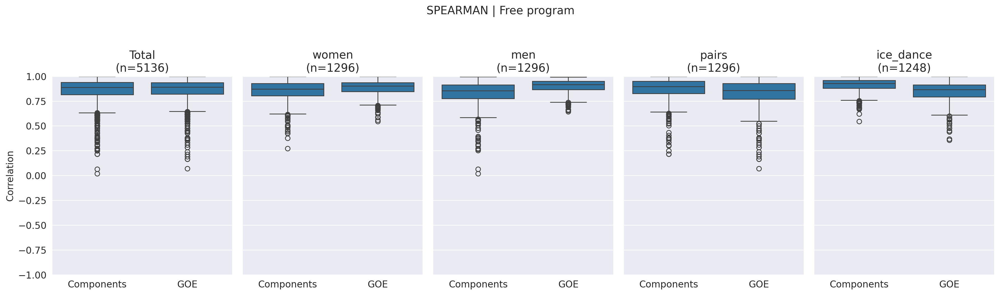

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

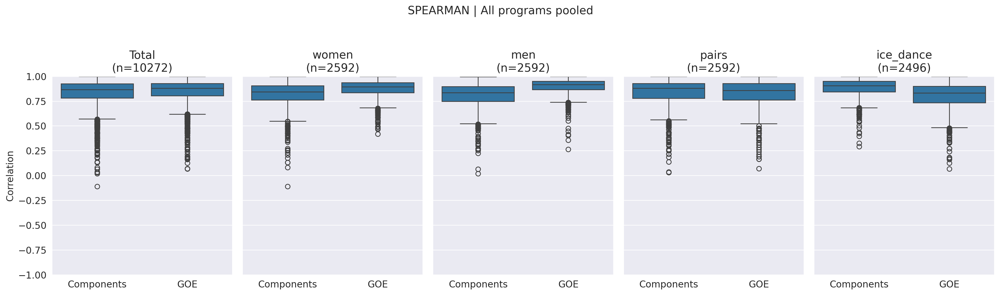

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

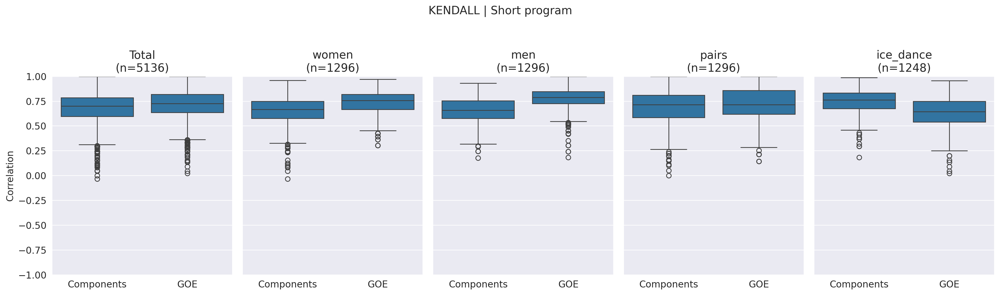

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

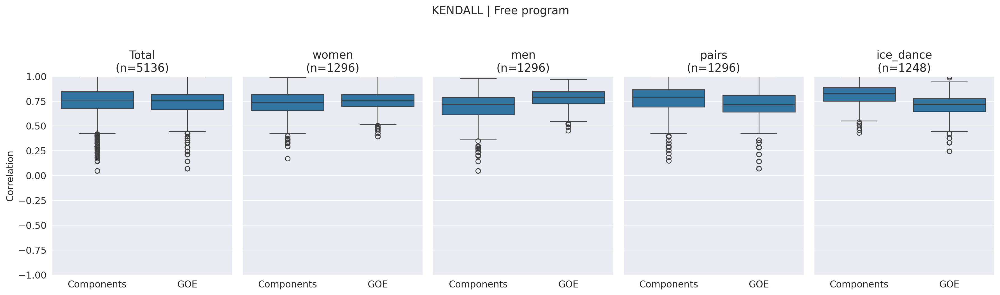

/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Components", "GOE"], rotation=0)
/tmp/ipykernel_71812/375257030.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of t

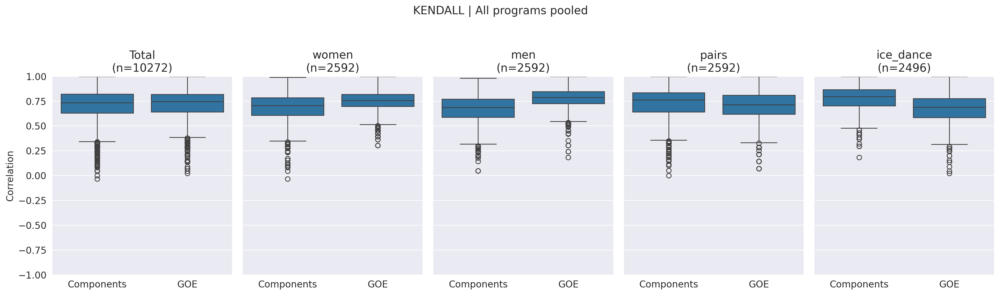

In [87]:
for method in ["pearson", "spearman", "kendall"]:
    plot_corr_overview_3programs_hue(
        corr_df,
        corr_method=method,
        score_types=("judge_component_score_norm", "judge_GOE"),
        category_order=("women", "men", "pairs", "ice_dance"),
        ylim=(-1, 1)
    )


In [ ]:
# --- 4) Run everything and save all figures
OUT_DIR = "figures/corr_boxplots"

custom_palette = {
    "judge_component_score_norm": "#1f77b4",  # blue
    "judge_GOE": "#d62728",                  # red
}

for method in ["pearson", "spearman", "kendall"]:
    plot_corr_overview_3programs_two_scores(
        corr_df=corr_df,
        corr_method=method,
        out_dir=OUT_DIR,
        category_order=("women", "men", "pairs", "ice_dance"),
        palette=custom_palette,
        ylim=(-1, 1),
        dpi=250
    )

/tmp/ipykernel_71812/102512813.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/102512813.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(score_labels), rotation=0)
/tmp/ipykernel_71812/102512813.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/102512813.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(score_labels), rotation=0)
/tmp/ipykernel_71812/102512813.py:57: FutureWarning: 

Passing `palette` without assigning

[SAVED] figures/corr_boxplots/box_components_vs_goe_all_programs_pearson_spearman_kendall.png


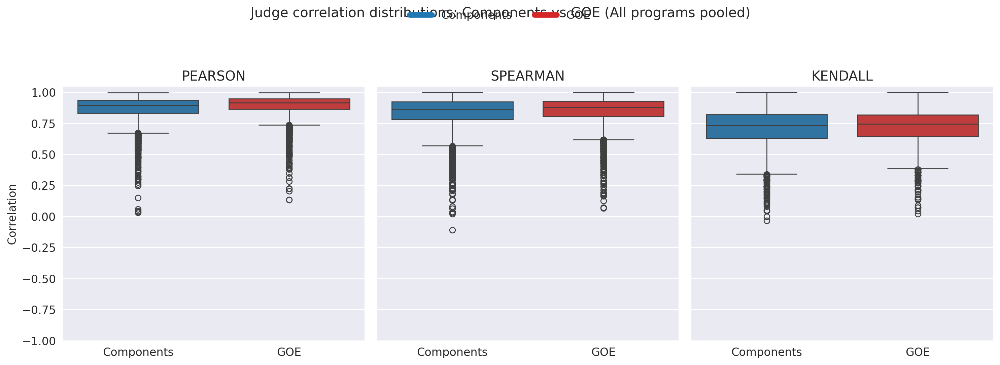

In [90]:
custom_palette = {
    "judge_component_score_norm": "#1f77b4",  # blue
    "judge_GOE": "#d62728",                  # red
}

plot_corr_methods_one_fig(
    corr_df=corr_df,
    out_dir="figures/corr_boxplots",
    filename="box_components_vs_goe_all_programs_pearson_spearman_kendall.png",
    palette=custom_palette,
    ylim=(-1, 1.05),
    figsize=(15, 5),
    dpi=300
)


/tmp/ipykernel_71812/3629606894.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/3629606894.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(score_labels), rotation=0)
/tmp/ipykernel_71812/3629606894.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_71812/3629606894.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(score_labels), rotation=0)
/tmp/ipykernel_71812/3629606894.py:44: FutureWarning: 

Passing `palette` without assi

[SAVED] figures/corr_boxplots/box_components_vs_goe_all_programs_pearson_spearman_kendall.png


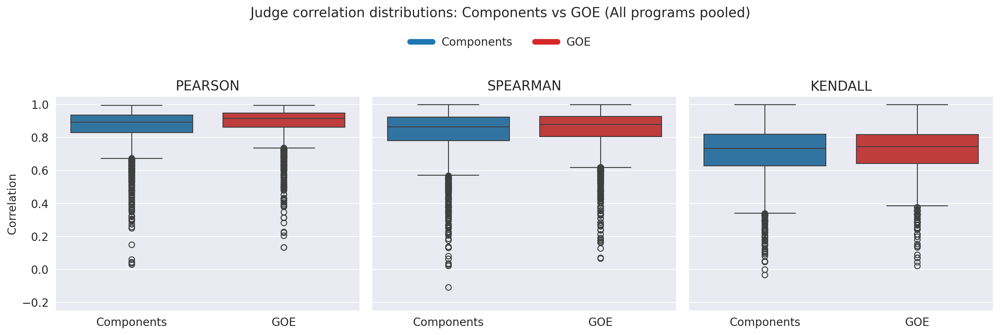

In [92]:
custom_palette = {
    "judge_component_score_norm": "#1f77b4",
    "judge_GOE": "#d62728",
}

plot_corr_methods_one_fig(
    corr_df=corr_df,
    out_dir="figures/corr_boxplots",
    filename="box_components_vs_goe_all_programs_pearson_spearman_kendall.png",
    palette=custom_palette,
    ylim=(-0.25, 1.05),
    figsize=(15, 5),
    dpi=300,
    title="Judge correlation distributions: Components vs GOE (All programs pooled)"
)
